# Experimentos de mejora del modelo
### Predicción de intención de compra en tiendas online

**Objetivo:** comprobar si podemos mehorar la capacidad predictiva de los modelos haciendo algunos cambios en los datos y en el entrenamiento.

Vamos a hacer 3 experimentos:

1. **Ingeniería de características:** crear nuevas variables a partir del comportamiento de navegación de los usuarios.

2. **Tratamiento del desequilibrio:** probar diferentes estrategias para ayudar a los modelos a encontrar mejor a los usuarios que realmente compran.
   
3. **Influencia de PageValues:** comparar los resultados de los modelos usando esta varibales y borrandola.

Partimos de las mejores configuraciones conseguidas en el notebook 02 y mantenemos Average Precision como métrica principal para comparar los resultados.

Para evitar usar información del conjunto de prueba durante los experimentos, usaremos solo los daos de entrenamiento y usaremos validación cruzada estratificada.

## 1. Preparación experimental

Para que podamos comparar los saultados con los de los notebooks anteriores, repetimos el mismo proceso de preparación de datos:
- Eliminación de duplicados
- Partición estratificada 80/20,
- Semilla 42.

Al principio nos centraremos en **Random Forest y CatBoost**, ya que fueron los dos modelos que tenían mejor Average Precision tras optimizar sus hiperparámetros en el notebook anterior.

Durante estos experimentos mantendremos fijos los hiperparámetros de ambos modelos. Así podremos comprobar si los cambios que hacemos en los datos o en el entrenamiento realmente mejoran los resultados sin que las diferencias se deban a un cambio en la configuración de los modelos.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from catboost import CatBoostClassifier

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

# Carga y división

RAIZ = Path.cwd().resolve()

if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

datos = pd.read_csv(
    RAIZ / "data" / "raw" / "online_shoppers_intention.csv"
)

datos = datos.drop_duplicates().reset_index(drop=True)

X = datos.drop(columns="Revenue")
y = datos["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

variables_categoricas = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

print(f"Entrenamiento: {len(X_train):,} sesiones")
print(f"Prueba: {len(X_test):,} sesiones")
print(f"Características originales: {X_train.shape[1]}")

Entrenamiento: 9,764 sesiones
Prueba: 2,441 sesiones
Características originales: 17


## 2. Ingeniería de características

### 2.1. Construcción de variables derivadas

A partir de lo que hemos visto en el análisis exploratorio, vamos a crear cinco características nuevas que podrían ayudar a los modelos a entender mejor el comportamiento de los usuarios durante la navegación:

- **Has_PageValue:** indicador de si PageValues es positivo.

- **Avg_Product_Time:** tiempo medio que un usuario está en cada página de producto.

- **Product_Page_Share:** proporción de las páginas visitadas corresponde a páginas de productos.

- **Total_Pages:** número total de páginas visitadas.

- **Total_Duration:** suma de las duraciones registradas.

La idea es que estas nuevas variables aporten información sobre tres aspectos: cúanto navega, cuánto tiempo dedica a ello y si su navegación está centrada en los productos.

In [2]:
def crear_caracteristicas(X):
    X = X.copy()

    X["Has_PageValue"] = (X["PageValues"] > 0).astype(int)

    X["Total_Pages"] = (
        X["Administrative"]
        + X["Informational"]
        + X["ProductRelated"]
    )

    X["Total_Duration"] = (
        X["Administrative_Duration"]
        + X["Informational_Duration"]
        + X["ProductRelated_Duration"]
    )

    X["Avg_Product_Time"] = np.where(
        X["ProductRelated"] > 0,
        X["ProductRelated_Duration"]
        / X["ProductRelated"].clip(lower=1),
        0
    )

    X["Product_Page_Share"] = (
        X["ProductRelated"]
        / X["Total_Pages"].clip(lower=1)
    )

    return X


X_train_fe = crear_caracteristicas(X_train)

print(f"Características originales: {X_train.shape[1]}")
print(f"Características ampliadas: {X_train_fe.shape[1]}")

nuevas_variables = [
    "Has_PageValue",
    "Avg_Product_Time",
    "Product_Page_Share",
    "Total_Pages",
    "Total_Duration"
]

display(
    X_train_fe[nuevas_variables]
    .describe()
    .round(2)
)

Características originales: 17
Características ampliadas: 22


,Has_PageValue,Avg_Product_Time,Product_Page_Share,Total_Pages,Total_Duration
count,9764.00,9764.00,9764.00,9764.00,9764.00
mean,0.22,38.38,0.90,34.95,1324.44
std,0.42,46.99,0.14,46.86,2054.21
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,17.97,0.86,9.00,231.95
50%,0.00,29.29,0.96,20.00,701.00
75%,0.00,45.67,1.00,42.00,1655.67
max,1.00,1411.00,1.00,746.00,69921.65


In [3]:
# Validación de las nuevas características

comprobaciones = pd.DataFrame({
    "Nulos": X_train_fe[nuevas_variables].isna().sum(),
    "Infinitos": np.isinf(
        X_train_fe[nuevas_variables]
    ).sum(),
    "Mínimo": X_train_fe[nuevas_variables].min(),
    "Máximo": X_train_fe[nuevas_variables].max()
})

display(comprobaciones.round(2))

,Nulos,Infinitos,Mínimo,Máximo
Has_PageValue,0,0,0.0,1.00
Avg_Product_Time,0,0,0.0,1411.00
Product_Page_Share,0,0,0.0,1.00
Total_Pages,0,0,0.0,746.00
Total_Duration,0,0,0.0,69921.65


**Comprobación de las características**

Hemos comprobado que las cinco nuevas variables derivadas se han calculado correctamente y que no tienen valores nulos ni infinitos.

Al revisar los valores obtenidos, vemos que en muchas sesiones una parte importante de las páginas visitadas son las de productos. También vemos algunos valores muy altos en las duraciones de navegación.

Por ahora vamos a conservar las cinco variables y comprobaremos si realmente ayudan a mejorar la capacidad predictiva o no.

### 2.3. Evaluación de las características derivadas

Vamos a comparar los resultados de Random Forest y CatBoost en dos situaciones:

- **Original:** las 17 características del dataset.
- **Ampliado:** las 17 originales y las 5 variables nuevas que hemos creado.

Para que la comparación sea justo tenemos que mantener los hiperparámetros y utilizar las mismas cinco particiones de validación cruzada estratificada.

La métrica que usaremos para comparar va a ser Average Precision. Así podemos comprobar si al añadir las nuevas variables mejoran los resultados.

In [5]:
resultados_fe = []

escenarios = [
    ("Originales (17)", X_train),
    ("Ampliadas (22)", X_train_fe)
]

for escenario, X_actual in escenarios:

    print(f"Evaluando {escenario}...")

    # Random Forest: One-Hot Encoding de las categóricas
    variables_numericas = [
        c for c in X_actual.columns
        if c not in variables_categoricas
    ]

    preprocesador_rf = ColumnTransformer([
        ("num", "passthrough", variables_numericas),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), variables_categoricas)
    ])

    modelo_rf = Pipeline([
        ("preprocesamiento", preprocesador_rf),
        ("clasificador", RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=8,
            max_features=0.5,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    evaluacion_rf = cross_validate(
        modelo_rf,
        X_actual,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1,
        error_score="raise"
    )

    # CatBoost: tratamiento nativo de categorías
    X_cat = X_actual.copy()

    for columna in variables_categoricas:
        X_cat[columna] = X_cat[columna].astype(str)

    modelo_cb = CatBoostClassifier(
        iterations=300,
        depth=8,
        learning_rate=0.03,
        l2_leaf_reg=3,
        loss_function="Logloss",
        random_seed=RANDOM_STATE,
        thread_count=4,
        verbose=False,
        allow_writing_files=False
    )

    evaluacion_cb = cross_validate(
        modelo_cb,
        X_cat,
        y_train,
        cv=cv,
        scoring="average_precision",
        params={"cat_features": variables_categoricas},
        n_jobs=1,
        error_score="raise"
    )

    # Guardar el AP de cada fold
    for nombre, evaluacion in [
        ("Random Forest", evaluacion_rf),
        ("CatBoost", evaluacion_cb)
    ]:
        for fold, ap in enumerate(
            evaluacion["test_score"], start=1
        ):
            resultados_fe.append({
                "Modelo": nombre,
                "Escenario": escenario,
                "Fold": fold,
                "AP": ap
            })

resultados_fe = pd.DataFrame(resultados_fe)

print("Evaluación completada.")

Evaluando Originales (17)...
Evaluando Ampliadas (22)...
Evaluación completada.


In [6]:
# Comparación del Average Precision medio

tabla_fe = (
    resultados_fe
    .groupby(["Modelo", "Escenario"])["AP"]
    .mean()
    .unstack()
)

tabla_fe = tabla_fe[
    ["Originales (17)", "Ampliadas (22)"]
]

tabla_fe["Diferencia AP"] = (
    tabla_fe["Ampliadas (22)"] -
    tabla_fe["Originales (17)"]
)

display(
    tabla_fe.style
    .format("{:.4f}")
    .background_gradient(
        subset=["Ampliadas (22)"],
        cmap="Blues"
    )
)

Escenario,Originales (17),Ampliadas (22),Diferencia AP
Modelo,,,
CatBoost,0.7519,0.7569,0.0051
Random Forest,0.7556,0.7551,-0.0005


### 2.4. Estabilidad de las mejoras

Ahora vamos a analizar cómo cambia el AP en cada uno de los cinco folds al añadir las 5 nuevas variables.

Para ello vamos a calcular la diferencia entre ambos resultados en cada partición
- **Valores positivos:** las nuevas variables mejoran el rendimiento.
- **Valores negativos:** las nuevas variables empeoran el rendimiento.

Así no solo veremos su el resultado medio mejora sino también si esa mejora se mantiene en las diferentes particiones o si depende demasiado de un fold concreto.

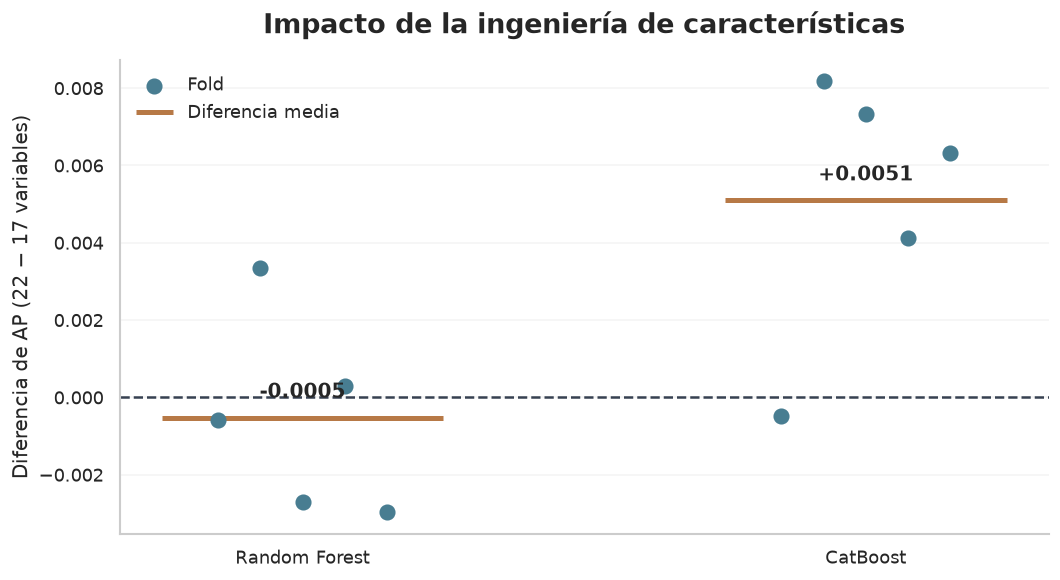

In [7]:
diferencias_fe = (
    resultados_fe
    .pivot(
        index=["Modelo", "Fold"],
        columns="Escenario",
        values="AP"
    )
    .reset_index()
)

diferencias_fe["Diferencia AP"] = (
    diferencias_fe["Ampliadas (22)"] -
    diferencias_fe["Originales (17)"]
)

fig, ax = plt.subplots(figsize=(9, 5))

modelos_orden = ["Random Forest", "CatBoost"]

for i, nombre in enumerate(modelos_orden):

    datos_modelo = diferencias_fe[
        diferencias_fe["Modelo"] == nombre
    ].sort_values("Fold")

    posiciones = i + np.linspace(-0.15, 0.15, 5)

    ax.scatter(
        posiciones,
        datos_modelo["Diferencia AP"],
        color="#487D91",
        s=75,
        zorder=3,
        label="Fold" if i == 0 else None
    )

    media = datos_modelo["Diferencia AP"].mean()

    ax.hlines(
        media,
        i - 0.25,
        i + 0.25,
        color="#B77946",
        linewidth=3,
        label="Diferencia media" if i == 0 else None
    )

    ax.annotate(
        f"{media:+.4f}",
        (i, media),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.axhline(
    0,
    color="#374151",
    linestyle="--",
    linewidth=1.5
)

ax.set_xticks(range(len(modelos_orden)))
ax.set_xticklabels(modelos_orden)

ax.set_ylabel("Diferencia de AP (22 − 17 variables)")
ax.set_title(
    "Impacto de la ingeniería de características",
    fontsize=16,
    pad=16
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

**Interpretación**

- **Random Forest:** añadir las cinco variables casi no mejora el resultado (ΔAP = −0,0005). Podemos ver tanto resultados positivos como negativos en los folds.
  
- **CatBoost:** el AP aumenta de 0,7519 a 0,7569 (ΔAP = +0,0051), y sí que mejora en cuatro de los cinco folds.

### 2.5. Aportación individual de las características derivadas

Como hemos visto, añadir las cinco variables ha dado resultados diferentes en Random Forest y CatBoost.

Para entender mejor qué es lo que está pasando vamos a probar cada variables por separado, vamos a ir añadiendo una a una.

Seguimos manteniendo los hiperparámetros optimizados y las 5 particiones de validación cruzada estratificada.

Con este esperimento podremos ver qué características nos dan más información y cuáles merece la pena combinar posteriormente.

In [8]:
resultados_individuales = []

for nombre in ["Random Forest", "CatBoost"]:

    for variable in nuevas_variables:

        print(f"Evaluando {nombre} + {variable}...")

        # Las 17 características originales y una nueva
        columnas = list(X_train.columns) + [variable]
        X_actual = X_train_fe[columnas].copy()

        if nombre == "Random Forest":

            numericas = [
                c for c in columnas
                if c not in variables_categoricas
            ]

            preprocesador = ColumnTransformer([
                ("num", "passthrough", numericas),
                ("cat", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ), variables_categoricas)
            ])

            modelo = Pipeline([
                ("preprocesamiento", preprocesador),
                ("clasificador", RandomForestClassifier(
                    n_estimators=300,
                    max_depth=8,
                    min_samples_leaf=8,
                    max_features=0.5,
                    random_state=RANDOM_STATE,
                    n_jobs=-1
                ))
            ])

            parametros_fit = {}

        else:

            # CatBoost utiliza directamente las categorías
            for columna in variables_categoricas:
                X_actual[columna] = X_actual[columna].astype(str)

            modelo = CatBoostClassifier(
                iterations=300,
                depth=8,
                learning_rate=0.03,
                l2_leaf_reg=3,
                loss_function="Logloss",
                random_seed=RANDOM_STATE,
                thread_count=4,
                verbose=False,
                allow_writing_files=False
            )

            parametros_fit = {
                "cat_features": variables_categoricas
            }

        evaluacion = cross_validate(
            modelo,
            X_actual,
            y_train,
            cv=cv,
            scoring="average_precision",
            params=parametros_fit,
            n_jobs=1,
            error_score="raise"
        )

        ap = evaluacion["test_score"].mean()
        ap_base = tabla_fe.loc[nombre, "Originales (17)"]

        resultados_individuales.append({
            "Modelo": nombre,
            "Variable": variable,
            "AP": ap,
            "Diferencia_AP": ap - ap_base
        })

resultados_individuales = pd.DataFrame(resultados_individuales)

print("\nEvaluación completada.")

Evaluando Random Forest + Has_PageValue...
Evaluando Random Forest + Avg_Product_Time...
Evaluando Random Forest + Product_Page_Share...
Evaluando Random Forest + Total_Pages...
Evaluando Random Forest + Total_Duration...
Evaluando CatBoost + Has_PageValue...
Evaluando CatBoost + Avg_Product_Time...
Evaluando CatBoost + Product_Page_Share...
Evaluando CatBoost + Total_Pages...
Evaluando CatBoost + Total_Duration...

Evaluación completada.


In [9]:
# Comparación de la aportación individual

tabla_individual = pd.DataFrame(index=nuevas_variables)

for nombre in ["Random Forest", "CatBoost"]:

    datos_modelo = (
        resultados_individuales[
            resultados_individuales["Modelo"] == nombre
        ]
        .set_index("Variable")
        .reindex(nuevas_variables)
    )

    tabla_individual[f"{nombre} · AP"] = datos_modelo["AP"]
    tabla_individual[f"{nombre} · ΔAP"] = datos_modelo["Diferencia_AP"]

display(
    tabla_individual.style
    .format({
        "Random Forest · AP": "{:.4f}",
        "Random Forest · ΔAP": "{:+.4f}",
        "CatBoost · AP": "{:.4f}",
        "CatBoost · ΔAP": "{:+.4f}"
    })
)

,Random Forest · AP,Random Forest · ΔAP,CatBoost · AP,CatBoost · ΔAP
Has_PageValue,0.7558,+0.0002,0.7538,+0.0020
Avg_Product_Time,0.7555,-0.0000,0.7509,-0.0009
Product_Page_Share,0.7544,-0.0012,0.7511,-0.0007
Total_Pages,0.7546,-0.0010,0.7511,-0.0007
Total_Duration,0.7532,-0.0024,0.7518,-0.0000


### 2.6. Comparación de la aportación individual

Hemos representado el cambio de Average Precision mediante un mapa de color.

El mapa de calor permite comparar de forma visual cómo afecta cada variable a Random Forest y CatBoost, identificar cuáles ofrecen mejores resultados y elegir las más interesantes para probar diferentes combinaciones.

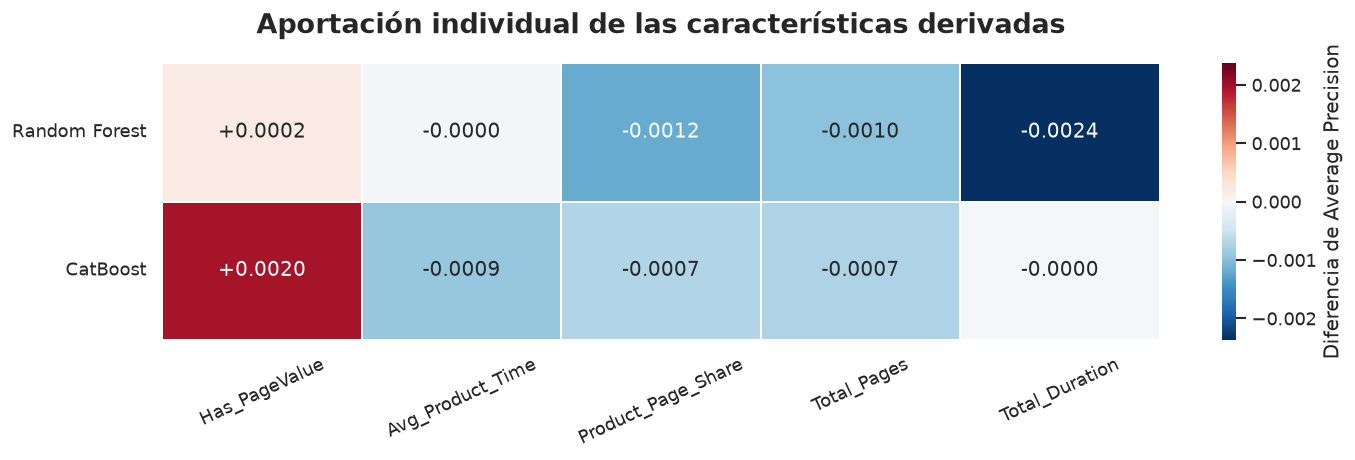

In [10]:
mapa_individual = resultados_individuales.pivot(
    index="Modelo",
    columns="Variable",
    values="Diferencia_AP"
).reindex(
    index=["Random Forest", "CatBoost"],
    columns=nuevas_variables
)

limite = np.abs(mapa_individual.to_numpy()).max()

fig, ax = plt.subplots(figsize=(12, 4))

sns.heatmap(
    mapa_individual,
    annot=True,
    fmt="+.4f",
    cmap="RdBu_r",
    center=0,
    vmin=-limite,
    vmax=limite,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Diferencia de Average Precision"},
    ax=ax
)

ax.set_title(
    "Aportación individual de las características derivadas",
    fontsize=16,
    pad=18
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=25)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

**Interpretación**

- **Random Forest:** ninguna de las 5 consigue mejorar significativamente el AP cuando se añade por separado. Por ello mantendremos las 17 variables originales para este modelo.
- **CatBoost:** Has_PageValue es la única que mejora el AP
  individualmente (+0,0020). Sin embargo, al añadir las cinco características a la vez, la mejora es mayor +0,0051.

**Decisión:** antes de elegir las variables definitivas para CatBoost vamos a investigar qué combinaciones de variables pueden explicar esa mejora conjunta.

### 2.7. Sustitución de PageValues por un indicador binario

En el análisis exploratorio vimos que existe una diferencia importante en la tasa de compra entre las sesiones en las que PageValues es igual a cero y las que tiene un valor positivo. Por ello queremos comprobar si concoer el valro exacto de PageValues nos aporta información adicional o basta con saber si es positivo o no.

1. **Original:** PageValues numérico, sin indicador.

2. **Ambas:** PageValues numérico y Has_PageValue, que nos dice si su valor es positivo.

3. **Solo binaria:** sustituimos PageValues por Has_PageValue.

Los dos primeros escenarios ya se han evaluado. Así que solo necesitamos entrenar el tercero, manteniendo los hiperparámetros optimizados y los mismos cinco folds.

Este experimento queremos comprobar si una representación más sencilla de PageValues mantiene su capacidad predictiva.

In [11]:
# Conservar las 16 variables restantes y añadir el indicador binario
X_binario = X_train.drop(columns=["PageValues"]).copy()

X_binario["Has_PageValue"] = (
    X_train["PageValues"] > 0
).astype(int)

# Preparación de las categorías para CatBoost
for columna in variables_categoricas:
    X_binario[columna] = X_binario[columna].astype(str)

modelo_cb_binario = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.03,
    l2_leaf_reg=3,
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

evaluacion_binaria = cross_validate(
    modelo_cb_binario,
    X_binario,
    y_train,
    cv=cv,
    scoring="average_precision",
    params={"cat_features": variables_categoricas},
    n_jobs=1,
    error_score="raise"
)

ap_binario = evaluacion_binaria["test_score"].mean()

print(f"Características utilizadas: {X_binario.shape[1]}")
print(f"AP con PageValues binario: {ap_binario:.4f}")

Características utilizadas: 17
AP con PageValues binario: 0.7463


#### Resultados de la sustitución

Comparamos el Average Precision de las tres representaciones de PageValues para ver si el indicador binario puede sustituir al valor numérico o si es mejor conservar ambos.

In [12]:
ap_original = tabla_fe.loc["CatBoost", "Originales (17)"]

ap_ambas = resultados_individuales.loc[
    (resultados_individuales["Modelo"] == "CatBoost") &
    (resultados_individuales["Variable"] == "Has_PageValue"),
    "AP"
].iloc[0]

tabla_pagevalues = pd.DataFrame({
    "Escenario": [
        "PageValues numérico",
        "PageValues + Has_PageValue",
        "Solo Has_PageValue"
    ],
    "Características": [17, 18, 17],
    "AP": [ap_original, ap_ambas, ap_binario]
})

tabla_pagevalues["Diferencia AP"] = (
    tabla_pagevalues["AP"] - ap_original
)

display(
    tabla_pagevalues.style
    .format({
        "AP": "{:.4f}",
        "Diferencia AP": "{:+.4f}"
    })
    .background_gradient(
        subset=["AP"],
        cmap="Blues"
    )
)

,Escenario,Características,AP,Diferencia AP
0,PageValues numérico,17,0.7519,+0.0000
1,PageValues + Has_PageValue,18,0.7538,+0.0020
2,Solo Has_PageValue,17,0.7463,-0.0056


**Interpretación**

- Sustituir `PageValues` por `Has_PageValue` reduce el AP de 0,7519 a 0,7463. Por lo que la magnitud de PageValues aporta información predictiva que la versión binaria pierde.
  
- Conservar ambas características mejora ligeramente el AP hasta 0,7538, aunque la mejora es pequeña (+0,0020).

**Decisión:** mantendremos `PageValues` como variable numérica. El indicador binario podría complementarla, pero no sustituirla.

### 2.8. Análisis de ablación en CatBoost

Al añadir las 5 variables conjuntamente, el AP de CatBoost mejora de 0,7519 a 0,7569. Pero cuando las probamos por separado la mayoría no mejora los resultados.

Para entender mejor qué aporta cada variables cuando se usan todas a la vez, vamos a hacer un análisis de ablación. Partimos de las 22 caracter´siticas y en cada prueba eliminamos una de las cinco para comprobar cómo cambia el rendimiento.

Mantenemos los hiperparámetros optimizados y los mismos cinco folds estratificados.

La interpretación de los resultados será la siguiente:
- Un cambio positivo de AP al eliminar una variable indicará que el modelo mejora sin ella. 
- Un cambio negativo indicará que su eliminación empeora el rendimiento.

In [13]:
ap_completo = tabla_fe.loc["CatBoost", "Ampliadas (22)"]

# Resultados por fold del modelo con las 22 características
ap_folds_completo = (
    resultados_fe[
        (resultados_fe["Modelo"] == "CatBoost") &
        (resultados_fe["Escenario"] == "Ampliadas (22)")
    ]
    .sort_values("Fold")["AP"]
    .to_numpy()
)

resultados_ablacion = []

for variable in nuevas_variables:

    print(f"Evaluando CatBoost sin {variable}...")

    # Partimos de las 22 características y eliminamos una
    X_actual = X_train_fe.drop(columns=[variable]).copy()

    for columna in variables_categoricas:
        X_actual[columna] = X_actual[columna].astype(str)

    modelo = CatBoostClassifier(
        iterations=300,
        depth=8,
        learning_rate=0.03,
        l2_leaf_reg=3,
        loss_function="Logloss",
        random_seed=RANDOM_STATE,
        thread_count=4,
        verbose=False,
        allow_writing_files=False
    )

    evaluacion = cross_validate(
        modelo,
        X_actual,
        y_train,
        cv=cv,
        scoring="average_precision",
        params={"cat_features": variables_categoricas},
        n_jobs=1,
        error_score="raise"
    )

    ap_folds = evaluacion["test_score"]
    ap_medio = ap_folds.mean()

    resultados_ablacion.append({
        "Variable eliminada": variable,
        "AP sin variable": ap_medio,
        "Cambio AP": ap_medio - ap_completo,
        "Folds que mejoran": int(
            np.sum(ap_folds > ap_folds_completo)
        )
    })

tabla_ablacion = (
    pd.DataFrame(resultados_ablacion)
    .sort_values("Cambio AP", ascending=False)
    .reset_index(drop=True)
)

print(f"\nAP con las 22 características: {ap_completo:.4f}")

display(
    tabla_ablacion.style
    .format({
        "AP sin variable": "{:.4f}",
        "Cambio AP": "{:+.4f}"
    })
    .background_gradient(
        subset=["Cambio AP"],
        cmap="RdBu_r",
        vmin=-0.01,
        vmax=0.01
    )
)

Evaluando CatBoost sin Has_PageValue...
Evaluando CatBoost sin Avg_Product_Time...
Evaluando CatBoost sin Product_Page_Share...
Evaluando CatBoost sin Total_Pages...
Evaluando CatBoost sin Total_Duration...

AP con las 22 características: 0.7569


,Variable eliminada,AP sin variable,Cambio AP,Folds que mejoran
0,Total_Duration,0.7558,-0.0012,2
1,Has_PageValue,0.7555,-0.0015,2
2,Total_Pages,0.7542,-0.0027,1
3,Avg_Product_Time,0.7537,-0.0033,0
4,Product_Page_Share,0.7535,-0.0035,1


**Interpretación**

- Eliminar cualquiera de las cinco características reduce el AP respecto al modelo completo (AP = 0,7569).

- Las mayores pérdidas aparecen al eliminar `Product_Page_Share` (−0,0035) y `Avg_Product_Time` (−0,0033).

- Esto nos indica que aunque algunas variables no mejoraban los resultados cuando se probaban por separado, sí que aportan información útil cuando se combinan con las demás.

**Decisión:** vamos a manetener provisionalmente las 22 características para CatBoost y las 17 originales para Random Forest.

Tenemos que tener en cuenta que las diferencias son pequeñas y tenemos que implementarlas con cuidado, ya que hemos utilizado los mismos folds para probar dsferentes combinaciones de variables. Por tanto será necesario comprobar estos resultados en una evaluación final independiente.

## 3. Tratamiento del desequilibrio de clases

Aproximadamente el 15,6 % de las sesiones termina en compra. Esto signidica que la mayotía de los usuarios no compra y que los modelos tienen muchos más ejemplos de la clase mayoritaria que de la minoritaria.

Este desequilibro puede hacer que los modelos tengan más dificultad para poder ver correctamente a los usuarios que sí que compran. Para intentar solucionarlo vamos a probar diferentes estrategias que dan más importancia a los compradores durante el entrenamiento.

### 3.1. Evaluación de estrategias de ponderación

Comparamos las siguientes opciones:

- **Random Forest:** sin ponderación de clases, `balanced` (más peso a la clase minoritaria en función de su frecuencia) y `balanced_subsample` (aplica esa ponderación teniendo en cuenta cada muestra utilizada para contruir árboles).
  
- **CatBoost:** sin ponderación de clases, `Balanced` (ajusta los pesos según el desequilibro entre las clases) y `SqrtBalanced` (aplica una ponderación más moderada utilizando la raíz cuadrada de ese desequilibrio).

Mantenemos los hiperparámetros optimizados, las características seleccionadas y los cinco folds estratificados.

Utilizamos Average Precision como métrica principal. Calculamos los pesos usando solo los datos de entrenamiento de cada fold.

In [15]:
resultados_pesos = []

# Random Forest: 17 características originales
numericas_rf = [
    c for c in X_train.columns
    if c not in variables_categoricas
]

preprocesador_rf = ColumnTransformer([
    ("num", "passthrough", numericas_rf),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), variables_categoricas)
])

for peso in ["balanced", "balanced_subsample"]:

    print(f"Evaluando Random Forest: {peso}")

    modelo = Pipeline([
        ("preprocesamiento", preprocesador_rf),
        ("clasificador", RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=8,
            max_features=0.5,
            class_weight=peso,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    evaluacion = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1,
        error_score="raise"
    )

    for fold, ap in enumerate(evaluacion["test_score"], start=1):
        resultados_pesos.append({
            "Modelo": "Random Forest",
            "Ponderación": peso,
            "Fold": fold,
            "AP": ap
        })


# CatBoost: 22 características
X_cat_pesos = X_train_fe.copy()

for columna in variables_categoricas:
    X_cat_pesos[columna] = X_cat_pesos[columna].astype(str)

for peso in ["Balanced", "SqrtBalanced"]:

    print(f"Evaluando CatBoost: {peso}")

    modelo = CatBoostClassifier(
        iterations=300,
        depth=8,
        learning_rate=0.03,
        l2_leaf_reg=3,
        auto_class_weights=peso,
        loss_function="Logloss",
        random_seed=RANDOM_STATE,
        thread_count=4,
        verbose=False,
        allow_writing_files=False
    )

    evaluacion = cross_validate(
        modelo,
        X_cat_pesos,
        y_train,
        cv=cv,
        scoring="average_precision",
        params={"cat_features": variables_categoricas},
        n_jobs=1,
        error_score="raise"
    )

    for fold, ap in enumerate(evaluacion["test_score"], start=1):
        resultados_pesos.append({
            "Modelo": "CatBoost",
            "Ponderación": peso,
            "Fold": fold,
            "AP": ap
        })

resultados_pesos = pd.DataFrame(resultados_pesos)

print("\nEvaluación completada.")

Evaluando Random Forest: balanced
Evaluando Random Forest: balanced_subsample
Evaluando CatBoost: Balanced
Evaluando CatBoost: SqrtBalanced

Evaluación completada.


In [16]:
# Comparación de estrategias de ponderación

referencias = (
    resultados_fe[
        (
            (resultados_fe["Modelo"] == "Random Forest") &
            (resultados_fe["Escenario"] == "Originales (17)")
        ) |
        (
            (resultados_fe["Modelo"] == "CatBoost") &
            (resultados_fe["Escenario"] == "Ampliadas (22)")
        )
    ][["Modelo", "Fold", "AP"]]
    .copy()
)

referencias["Ponderación"] = "Sin pesos"

todos_pesos = pd.concat(
    [referencias, resultados_pesos],
    ignore_index=True
)

tabla_pesos = (
    todos_pesos
    .groupby(["Modelo", "Ponderación"])["AP"]
    .agg(["mean", "std"])
    .rename(columns={"mean": "AP medio", "std": "Desv. AP"})
)

display(
    tabla_pesos.style
    .format("{:.4f}")
    .background_gradient(
        subset=["AP medio"],
        cmap="Blues"
    )
)

### 3.2. Resultados y comparación

Comparamos el Average Precision medio y su desviación estándar para cada una de las estrategias de ponderación.

También analizamos cuánto cambia el resultado en cada fold respecto al modelo original, el que no usa pesos para las clases. De esta manera podemos comprobar no solo qué estrategia tiene mejor resultado medio, sino también si las mejoras se mantienen en las distintas particiones.

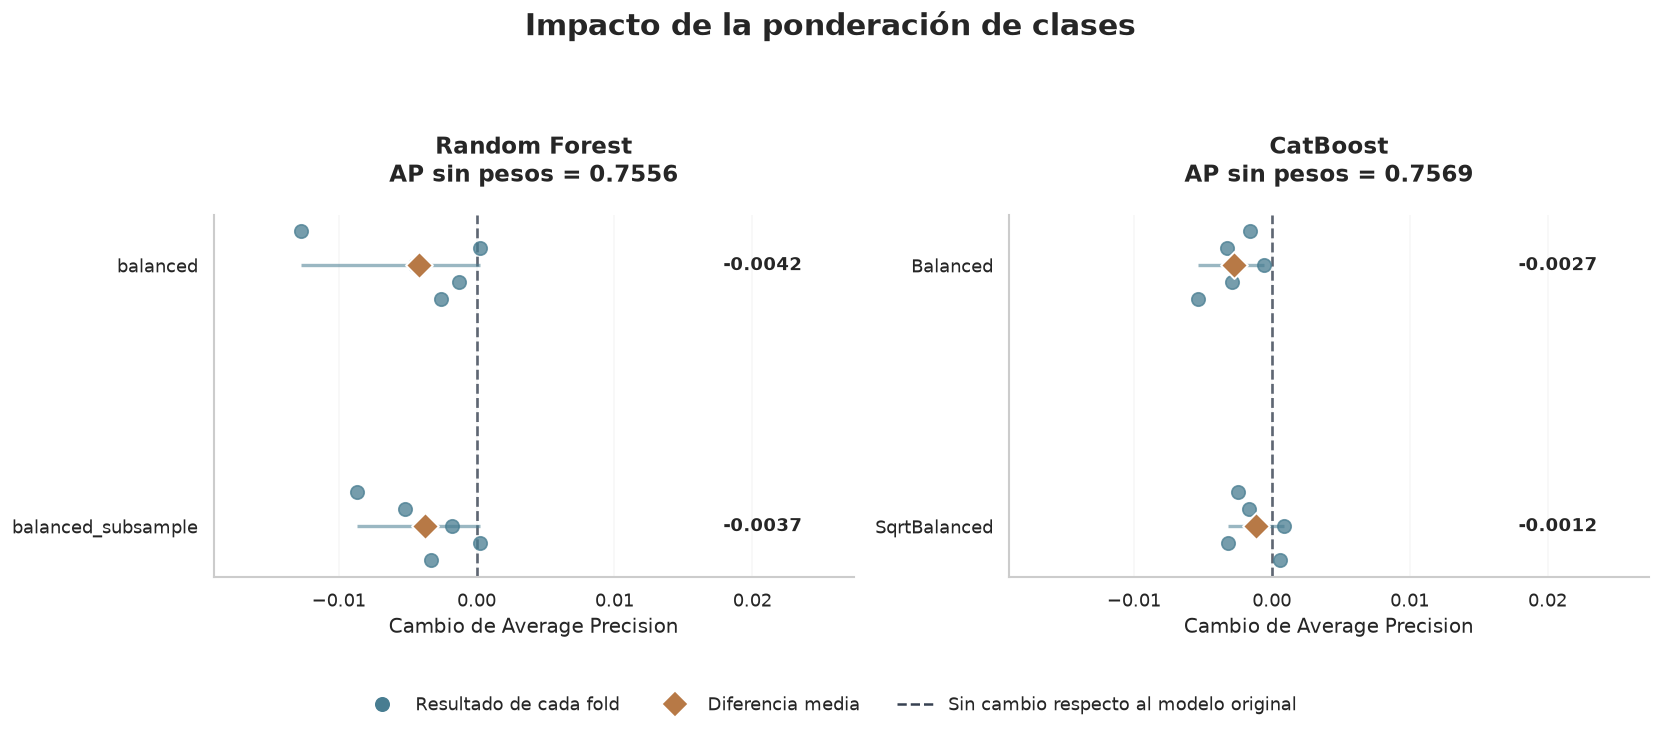

In [17]:
from matplotlib.lines import Line2D

configuraciones = {
    "Random Forest": ["balanced", "balanced_subsample"],
    "CatBoost": ["Balanced", "SqrtBalanced"]
}

# Calcular diferencias emparejadas respecto al modelo sin pesos
diferencias_pesos = {}

for nombre, estrategias in configuraciones.items():

    tabla = (
        todos_pesos[todos_pesos["Modelo"] == nombre]
        .pivot(index="Fold", columns="Ponderación", values="AP")
        .sort_index()
    )

    for estrategia in estrategias:
        diferencias_pesos[(nombre, estrategia)] = (
            tabla[estrategia] - tabla["Sin pesos"]
        ).to_numpy()

# Escala compartida para facilitar la comparación
limite = max(
    np.max(np.abs(valores))
    for valores in diferencias_pesos.values()
) * 1.3

limite = max(limite, 0.002)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (nombre, estrategias) in zip(
    axes, configuraciones.items()
):

    # Referencia: ninguna mejora ni empeoramiento
    ax.axvline(
        0,
        color="#374151",
        linestyle="--",
        linewidth=1.6,
        alpha=0.8
    )

    ap_referencia = tabla_pesos.loc[
        (nombre, "Sin pesos"), "AP medio"
    ]

    for i, estrategia in enumerate(estrategias):

        diferencias = diferencias_pesos[(nombre, estrategia)]
        media = diferencias.mean()

        # Rango de diferencias observado entre folds
        ax.hlines(
            i,
            diferencias.min(),
            diferencias.max(),
            color="#487D91",
            linewidth=2,
            alpha=0.55
        )

        # Cinco folds individuales
        posiciones = i + np.linspace(-0.13, 0.13, 5)

        ax.scatter(
            diferencias,
            posiciones,
            color="#487D91",
            s=65,
            alpha=0.75,
            zorder=3
        )

        # Media destacada
        ax.scatter(
            media,
            i,
            marker="D",
            s=130,
            color="#B77946",
            edgecolor="white",
            linewidth=1.2,
            zorder=5
        )

        # Valor numérico de la diferencia media
        ax.text(
            limite * 1.08,
            i,
            f"{media:+.4f}",
            va="center",
            ha="left",
            fontsize=11,
            fontweight="bold"
        )

    ax.set_yticks(range(len(estrategias)))
    ax.set_yticklabels(estrategias)
    ax.invert_yaxis()

    ax.set_xlim(-limite * 1.15, limite * 1.65)

    ax.set_title(
        f"{nombre}\nAP sin pesos = {ap_referencia:.4f}",
        fontsize=14,
        pad=20
    )

    ax.set_xlabel("Cambio de Average Precision")
    ax.grid(axis="x", alpha=0.15)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Impacto de la ponderación de clases",
    fontsize=18,
    fontweight="bold",
    y=1.08
)

leyenda = [
    Line2D(
        [0], [0],
        marker="o", linestyle="None",
        color="#487D91",
        markersize=8,
        label="Resultado de cada fold"
    ),
    Line2D(
        [0], [0],
        marker="D", linestyle="None",
        color="#B77946",
        markersize=9,
        label="Diferencia media"
    ),
    Line2D(
        [0], [0],
        linestyle="--",
        color="#374151",
        label="Sin cambio respecto al modelo original"
    )
]

fig.legend(
    handles=leyenda,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.show()

**Interpretación**

- **Random Forest:** las dos estrategias reducen el AP respecto al modelo sin pesos (0,7556). `balanced` tiene 0,7514 y `balanced_subsample` 0,7519, con pérdidas en la mayoría de folds.

- **CatBoost:** tampoco mejora con ponderación. `Balanced` reduce el AP a 0,7542, mientras que `SqrtBalanced` alcanza 0,7558, muy cercano al valor original (0,7569).
- La diferencia entre los folds son pequeñas, pero ninguna estrategia consigue una mejora consistente respecto a su referencia..

**Decisión:** mantenemos ambos modelos sin ponderación de clases ya que ninguna alternativa mejora nuestra métrica principal, AP.

### 3.2. Sobremuestreo de la clase minoritaria

Como la ponderación no ha mejorado el AP, vamos a ver otra alternativa: Random Oversampling. Esta técnica aumenta el número de observaciones de la clase minoritaria duplicando algunas de ellas de forma aleatoria.

Vamos a probar dos niveles de sobremuestreo:

- **Parcial (0,5):** una sesión compradora por cada dos sesiones no compradoras.
- **Completa (1,0):** el mismo número de sesiones compradoras y no compradoras.

Es importante aplicar el sobremuestreo solo a los datos de entrenamiento de cada fold. Para ello usamos un Pipeline de imbalanced-learn, así evitamos que los datos de validación se vean afectados y mantenemos su distribución original.

In [18]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline


resultados_muestreo = []

for proporcion in [0.5, 1.0]:

    print(f"Evaluando Random Forest: oversampling {proporcion}")

    modelo_rf_ros = ImbPipeline([
        ("muestreo", RandomOverSampler(
            sampling_strategy=proporcion,
            random_state=RANDOM_STATE
        )),
        ("preprocesamiento", preprocesador_rf),
        ("clasificador", RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=8,
            max_features=0.5,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    evaluacion_rf = cross_validate(
        modelo_rf_ros,
        X_train,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1,
        error_score="raise"
    )

    print(f"Evaluando CatBoost: oversampling {proporcion}")

    modelo_cb_ros = ImbPipeline([
        ("muestreo", RandomOverSampler(
            sampling_strategy=proporcion,
            random_state=RANDOM_STATE
        )),
        ("clasificador", CatBoostClassifier(
            iterations=300,
            depth=8,
            learning_rate=0.03,
            l2_leaf_reg=3,
            loss_function="Logloss",
            random_seed=RANDOM_STATE,
            thread_count=4,
            verbose=False,
            allow_writing_files=False
        ))
    ])

    evaluacion_cb = cross_validate(
        modelo_cb_ros,
        X_cat_pesos,
        y_train,
        cv=cv,
        scoring="average_precision",
        params={
            "clasificador__cat_features": variables_categoricas
        },
        n_jobs=1,
        error_score="raise"
    )

    for nombre, evaluacion in [
        ("Random Forest", evaluacion_rf),
        ("CatBoost", evaluacion_cb)
    ]:
        for fold, ap in enumerate(
            evaluacion["test_score"], start=1
        ):
            resultados_muestreo.append({
                "Modelo": nombre,
                "Muestreo": f"Oversampling {proporcion}",
                "Fold": fold,
                "AP": ap
            })

resultados_muestreo = pd.DataFrame(resultados_muestreo)

print("\nEvaluación completada.")

Evaluando Random Forest: oversampling 0.5
Evaluando CatBoost: oversampling 0.5
Evaluando Random Forest: oversampling 1.0
Evaluando CatBoost: oversampling 1.0

Evaluación completada.


### 3.3. Comparación de las estrategias de balanceo

Comparamos los resultados del sobremuestreo con los modelos originales sin balanceo.

Analizamos el Average Precision medio y su variabilidad, manteniendo las mismas particiones de validación cruzada.

In [19]:
tabla_muestreo = (
    resultados_muestreo
    .groupby(["Modelo", "Muestreo"])["AP"]
    .agg(["mean", "std"])
    .rename(columns={
        "mean": "AP medio",
        "std": "Desv. AP"
    })
)

ap_referencia = {
    "Random Forest": tabla_fe.loc[
        "Random Forest", "Originales (17)"
    ],
    "CatBoost": tabla_fe.loc[
        "CatBoost", "Ampliadas (22)"
    ]
}

tabla_muestreo["AP sin balanceo"] = [
    ap_referencia[modelo]
    for modelo in tabla_muestreo.index.get_level_values("Modelo")
]

tabla_muestreo["Cambio AP"] = (
    tabla_muestreo["AP medio"] -
    tabla_muestreo["AP sin balanceo"]
)

display(
    tabla_muestreo.style
    .format({
        "AP medio": "{:.4f}",
        "Desv. AP": "{:.4f}",
        "AP sin balanceo": "{:.4f}",
        "Cambio AP": "{:+.4f}"
    })
    .background_gradient(
        subset=["AP medio"],
        cmap="Blues"
    )
)

**Interpretación**

- Random Oversampling no mejora el Average Precision de ninguno de los dos modelos.
  
- El sobremuestreo parcial (0,5) tiene mejores resultados que el balanceo completo (1,0), especialmente en CatBoost.

**Decisión:** mantenemos como referencia los modelos sin balanceo y vamos a probar SMOTENC. Así podemos ver si generar sesiones sentéticas da mejores resultados que simplemente duplicar las sesiones de la clase minoritaria.

### 3.3. Sobremuestreo sintético mediante SMOTENC

SMOTENC es una variante de SMOTE pensada para conjuntos que mezclan tanto variables numéricas  como categóricas.

A diferencia de Random Oversampling que solo duplica sesiones existentes, SMOTENC genera nuevas sesiones sintéticas a partir de sesiones compradoras similares. Probaremos dos niveles de balanceo: 0,5 y 1,0.

Antes de aplicar la técnica, transdormamos temporalmente las variables numéricas mediante QuantileTransformer. Essto nos ayuda a que las diferencias de escala entre variables no distorsionen la búsqueda de sesiones similares.

El procedimiento se repite dentro de cada fold:

1. Ajustamos la transformación con los datos de entrenamiento.
2. Aplicamos SMOTENC solo sobre esos datos.
3. Recuperamos las unidades originales y recalculamos las características derivadas de CatBoost.
4. Entrenamos el modelo y lo evaluamos con el conjunto de validación original.

Hay que tener en cuenta que las sesiones generadas son aproximaciones y no tienen por qué cumplir todas las condiciones del comportamiento real de los usuarios.

In [20]:
from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import average_precision_score
from sklearn.base import clone


numericas_originales = [
    c for c in X_train.columns
    if c not in variables_categoricas
]

resultados_smotenc = []

for proporcion in [0.5, 1.0]:

    print(f"\nSMOTENC con proporción {proporcion}")

    for fold, (idx_train, idx_val) in enumerate(
        cv.split(X_train, y_train), start=1
    ):

        X_ent = X_train.iloc[idx_train].copy()
        y_ent = y_train.iloc[idx_train]

        X_val = X_train.iloc[idx_val].copy()
        y_val = y_train.iloc[idx_val]

        # 1. Escalado temporal, ajustado solo con el fold
        escalador = QuantileTransformer(
            n_quantiles=min(1000, len(X_ent)),
            output_distribution="uniform",
            random_state=RANDOM_STATE
        )

        X_escalado = X_ent.copy()
        X_escalado[numericas_originales] = (
            escalador.fit_transform(
                X_ent[numericas_originales]
            )
        )

        # 2. Generación sintética solo en entrenamiento
        smotenc = SMOTENC(
            categorical_features=variables_categoricas,
            sampling_strategy=proporcion,
            k_neighbors=5,
            random_state=RANDOM_STATE
        )

        X_res, y_res = smotenc.fit_resample(
            X_escalado, y_ent
        )

        # 3. Recuperar las unidades originales
        X_res[numericas_originales] = (
            escalador.inverse_transform(
                X_res[numericas_originales]
            )
        )

        # Los recuentos de páginas deben ser enteros
        for columna in [
            "Administrative", "Informational", "ProductRelated"
        ]:
            X_res[columna] = (
                X_res[columna].clip(lower=0).round().astype(int)
            )

        # 4A. Random Forest: 17 características
        modelo_rf_smote = Pipeline([
            ("preprocesamiento", clone(preprocesador_rf)),
            ("clasificador", RandomForestClassifier(
                n_estimators=300,
                max_depth=8,
                min_samples_leaf=8,
                max_features=0.5,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])

        modelo_rf_smote.fit(X_res, y_res)

        probs_rf = modelo_rf_smote.predict_proba(X_val)[:, 1]

        resultados_smotenc.append({
            "Modelo": "Random Forest",
            "Muestreo": f"SMOTENC {proporcion}",
            "Fold": fold,
            "AP": average_precision_score(y_val, probs_rf)
        })

        # 4B. CatBoost: crear las 5 características después de SMOTENC
        X_res_cb = crear_caracteristicas(X_res)
        X_val_cb = crear_caracteristicas(X_val)

        for columna in variables_categoricas:
            X_res_cb[columna] = X_res_cb[columna].astype(str)
            X_val_cb[columna] = X_val_cb[columna].astype(str)

        modelo_cb_smote = CatBoostClassifier(
            iterations=300,
            depth=8,
            learning_rate=0.03,
            l2_leaf_reg=3,
            loss_function="Logloss",
            random_seed=RANDOM_STATE,
            thread_count=4,
            verbose=False,
            allow_writing_files=False
        )

        modelo_cb_smote.fit(
            X_res_cb,
            y_res,
            cat_features=variables_categoricas
        )

        probs_cb = modelo_cb_smote.predict_proba(X_val_cb)[:, 1]

        resultados_smotenc.append({
            "Modelo": "CatBoost",
            "Muestreo": f"SMOTENC {proporcion}",
            "Fold": fold,
            "AP": average_precision_score(y_val, probs_cb)
        })

    print(f"Proporción {proporcion} completada.")

resultados_smotenc = pd.DataFrame(resultados_smotenc)

print("\nEvaluación SMOTENC completada.")


SMOTENC con proporción 0.5
Proporción 0.5 completada.

SMOTENC con proporción 1.0
Proporción 1.0 completada.

Evaluación SMOTENC completada.


#### Resultados de SMOTENC

Comparamos las dos intensidades de SMOTENC con los modelos originales sin balanceo.

El objetivo es ver si generar sesiones sintéticas de compradores mejora Average Precision respecto a las estrategias anteriores.

In [21]:
tabla_smotenc = (
    resultados_smotenc
    .groupby(["Modelo", "Muestreo"])["AP"]
    .agg(["mean", "std"])
    .rename(columns={
        "mean": "AP medio",
        "std": "Desv. AP"
    })
)

tabla_smotenc["AP sin balanceo"] = [
    ap_referencia[modelo]
    for modelo in tabla_smotenc.index.get_level_values("Modelo")
]

tabla_smotenc["Cambio AP"] = (
    tabla_smotenc["AP medio"] -
    tabla_smotenc["AP sin balanceo"]
)

display(
    tabla_smotenc.style
    .format({
        "AP medio": "{:.4f}",
        "Desv. AP": "{:.4f}",
        "AP sin balanceo": "{:.4f}",
        "Cambio AP": "{:+.4f}"
    })
    .background_gradient(
        subset=["AP medio"],
        cmap="Blues"
    )
)

**Interpretación**

- **Random Forest:** SMOTENC reduce el AP de 0,7556 a 0,7402 con balanceo parcial y a 0,7251 con balanceo completo.

- **CatBoost:** la pérdida es todavía mayor, pasando de 0,7569 a 0,7298 y 0,7067.
- En ambos modelos, SMOTENC obtiene peores resultados que Random Oversampling, especialmente con balanceo completo.

**Decisión:** descartamos SMOTENC con las configuraciones actuales. Random Oversampling parcial ha dado los resultados más cercanos a los modelos originales, por lo que vamos a ver su podemos mejorar el rendimiento de Random Forest reajustando sus hiperparámetros.

### 3.4. Optimización con Random Oversampling

De todas las estrategias de remuestreo que hemos ido probando Random Oversampling parcial es la que ha tenido resultados mas parecidos al modelo original. Sin embargo, hasta ahora hemos utilizado los hiperparámetros optimizados para los datos sin balancera. Por eso vamos a probar si podemos conseguir mejores resultados ajustandolos para trabajar con sobremuestreo.

Para ello vamos a hacer una búsqueda reducida de dos hiperperámetros:
- **max_depth:** profundidades de 6, 8 y 12.

- **min_samples_leaf:** tamaños mínimos de hoja de 4, 8 y 12.

Mantendremos 300 árboles, max_features=0.5 y una proporción de sobremuestreo de 0,5.

El remuestreo se aplicará dentro del Pipeline para que solo afecte al entrenamiento de cada fold.

Seleccionaremos la configuración con mayor Average Precision.

In [23]:
from sklearn.model_selection import GridSearchCV

modelo_rf_ros = ImbPipeline([
    ("muestreo", RandomOverSampler(
        sampling_strategy=0.5,
        random_state=RANDOM_STATE
    )),
    ("preprocesamiento", preprocesador_rf),
    ("clasificador", RandomForestClassifier(
        n_estimators=300,
        max_features=0.5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

parametros_rf_ros = {
    "clasificador__max_depth": [6, 8, 12],
    "clasificador__min_samples_leaf": [4, 8, 12]
}

busqueda_rf_ros = GridSearchCV(
    estimator=modelo_rf_ros,
    param_grid=parametros_rf_ros,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_rf_ros.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda_rf_ros.best_params_)

print(
    f"\nAP sin balanceo: "
    f"{tabla_fe.loc['Random Forest', 'Originales (17)']:.4f}"
)

print(
    f"AP oversampling inicial: "
    f"{tabla_muestreo.loc[('Random Forest', 'Oversampling 0.5'), 'AP medio']:.4f}"
)

print(f"AP oversampling optimizado: {busqueda_rf_ros.best_score_:.4f}")

Mejores hiperparámetros:
{'clasificador__max_depth': 8, 'clasificador__min_samples_leaf': 12}

AP sin balanceo: 0.7556
AP oversampling inicial: 0.7532
AP oversampling optimizado: 0.7554


#### Resultados de la optimización con sobremuestreo

Hemos representado el Average Precision de las nueve combinaciones mediante un mapa de calor.

El objetivo es ver si adaptar la complejidad de los árboles al sobremuestreo nos permite recuperar o mejorar el rendimiento del modelo sin balanceo.

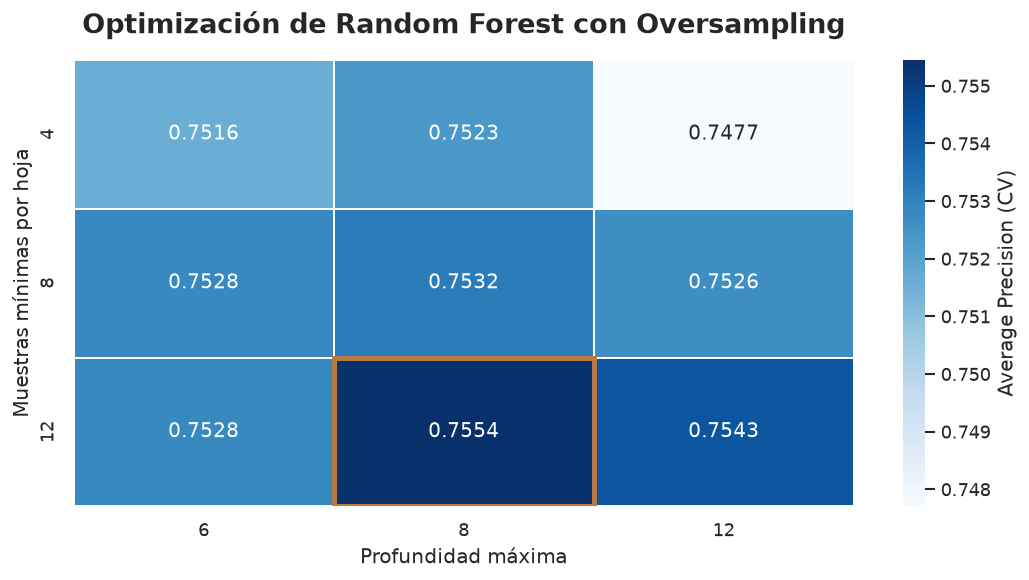

In [24]:
resultados_ros = pd.DataFrame(busqueda_rf_ros.cv_results_)

resultados_ros["Profundidad"] = (
    resultados_ros["param_clasificador__max_depth"].astype(int)
)

resultados_ros["Muestras por hoja"] = (
    resultados_ros["param_clasificador__min_samples_leaf"].astype(int)
)

mapa_ros = resultados_ros.pivot(
    index="Muestras por hoja",
    columns="Profundidad",
    values="mean_test_score"
).reindex(
    index=[4, 8, 12],
    columns=[6, 8, 12]
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(
    mapa_ros,
    annot=True,
    fmt=".4f",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Average Precision (CV)"},
    ax=ax
)

# Resaltar la mejor configuración
mejor_fila, mejor_columna = np.unravel_index(
    np.nanargmax(mapa_ros.to_numpy()),
    mapa_ros.shape
)

ax.add_patch(
    plt.Rectangle(
        (mejor_columna, mejor_fila),
        1, 1,
        fill=False,
        edgecolor="#B77946",
        linewidth=3
    )
)

ax.set_title(
    "Optimización de Random Forest con Oversampling",
    fontsize=16,
    pad=16
)

ax.set_xlabel("Profundidad máxima")
ax.set_ylabel("Muestras mínimas por hoja")

plt.tight_layout()
plt.show()

#### Refinamiento final del sobremuestreo

La primera búsqueda ha mejorado el AP hasta 0,7554, prácticamente igualando el modelo sin balanceo (0,7556).

El mejor resultado es con max_depth=8 y min_samples_leaf=12, en el extremo superior del rango visto para este parámetro.

Fijamos la profundidad en 8 y aumentamos únicamente min_samples_leaf para ver si una mayor regularización mejora el rendimiento.

In [25]:
from sklearn.base import clone

modelo_ros_final = clone(modelo_rf_ros).set_params(
    clasificador__max_depth=8
)

parametros_ros_final = {
    "clasificador__min_samples_leaf": [8, 12, 16, 20, 24]
}

busqueda_ros_final = GridSearchCV(
    estimator=modelo_ros_final,
    param_grid=parametros_ros_final,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_ros_final.fit(X_train, y_train)

ap_sin_balanceo = tabla_fe.loc[
    "Random Forest", "Originales (17)"
]

print("Mejores hiperparámetros:")
print(busqueda_ros_final.best_params_)

print(f"\nAP sin balanceo: {ap_sin_balanceo:.4f}")
print(f"AP búsqueda anterior: {busqueda_rf_ros.best_score_:.4f}")
print(f"AP refinamiento final: {busqueda_ros_final.best_score_:.4f}")

Mejores hiperparámetros:
{'clasificador__min_samples_leaf': 20}

AP sin balanceo: 0.7556
AP búsqueda anterior: 0.7554
AP refinamiento final: 0.7558


#### Resultados del refinamiento final

Comparamos el Average Precision obtenido con distintos tamaños mínimos de hoja, manteniendo fijos el resto de hiperparámetros y la proporción de sobremuestreo.

Incluimos como referencia el rendimiento del modelo sin balanceo para comprobar si el reajuste de hiperparámetros justifica utilizar Oversampling.

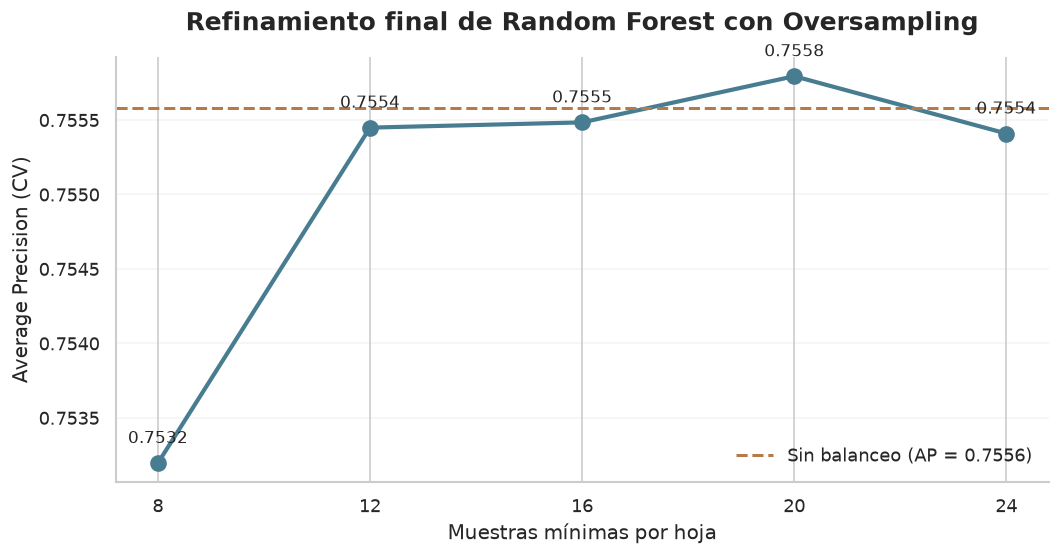

In [26]:
resultados_ros_final = pd.DataFrame(
    busqueda_ros_final.cv_results_
)

resultados_ros_final["Muestras por hoja"] = (
    resultados_ros_final[
        "param_clasificador__min_samples_leaf"
    ].astype(int)
)

resultados_ros_final = resultados_ros_final.sort_values(
    "Muestras por hoja"
)

fig, ax = plt.subplots(figsize=(9, 4.8))

ax.plot(
    resultados_ros_final["Muestras por hoja"],
    resultados_ros_final["mean_test_score"],
    color="#487D91",
    marker="o",
    markersize=9,
    linewidth=2.5
)

ax.axhline(
    ap_sin_balanceo,
    color="#B77946",
    linestyle="--",
    linewidth=1.8,
    label=f"Sin balanceo (AP = {ap_sin_balanceo:.4f})"
)

for _, fila in resultados_ros_final.iterrows():
    ax.annotate(
        f'{fila["mean_test_score"]:.4f}',
        (fila["Muestras por hoja"], fila["mean_test_score"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

ax.set_xticks([8, 12, 16, 20, 24])
ax.set_xlabel("Muestras mínimas por hoja")
ax.set_ylabel("Average Precision (CV)")

ax.set_title(
    "Refinamiento final de Random Forest con Oversampling",
    fontsize=15,
    pad=16
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

**Interpretación**

- El mejor resultado se obtiene con `min_samples_leaf=20`, alcanzando un AP de 0,7558, frente al 0,7556 del modelo original sin balanceo.

- Los valores entre 12 y 24 tienen resultados muy similares, lo que nos indica una región de rendimiento estable.

  
- La mejora de solo +0,0002 no justifica incorporar el sobremuestreo, especialmente si tenemos en cuenta el coste adicional y el proceso de selección de hiperparámetros.

**Decisión:** conservamos Random Forest sin balanceo.

### 3.5. Comparación global de las estrategias de balanceo

Comparamos las estrategias evaluadas en Random Forest y CatBoost:
ponderación de clases, Random Oversampling y SMOTENC.

Incluimos también el resultado del reajuste de hiperparámetros
con sobremuestreo parcial en Random Forest.

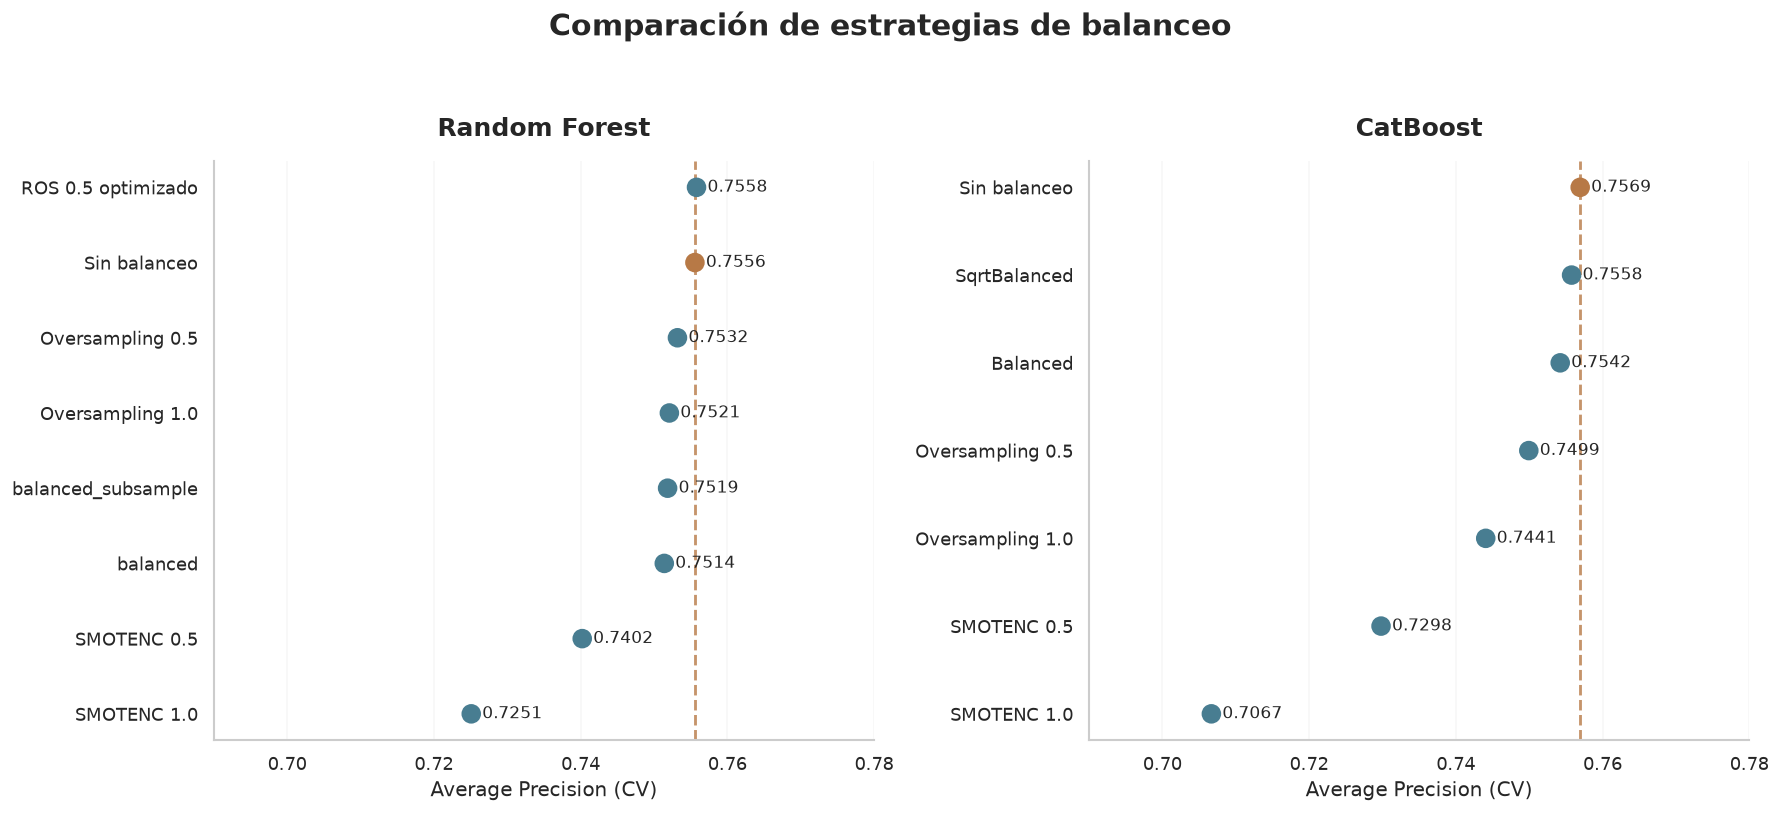

In [27]:
# Recuperar los resultados de los experimentos anteriores
df_referencias = referencias.copy()
df_referencias["Estrategia"] = "Sin balanceo"

df_pesos = resultados_pesos.rename(
    columns={"Ponderación": "Estrategia"}
)

df_ros = resultados_muestreo.rename(
    columns={"Muestreo": "Estrategia"}
)

df_smote = resultados_smotenc.rename(
    columns={"Muestreo": "Estrategia"}
)

# Recuperar los folds de la mejor configuración con ROS
mejor_indice = busqueda_ros_final.best_index_

df_ros_optimizado = pd.DataFrame({
    "Modelo": "Random Forest",
    "Estrategia": "ROS 0.5 optimizado",
    "Fold": np.arange(1, 6),
    "AP": [
        busqueda_ros_final.cv_results_[
            f"split{i}_test_score"
        ][mejor_indice]
        for i in range(5)
    ]
})

# Reunir todos los resultados
resultados_balanceo = pd.concat([
    df_referencias[["Modelo", "Estrategia", "Fold", "AP"]],
    df_pesos[["Modelo", "Estrategia", "Fold", "AP"]],
    df_ros[["Modelo", "Estrategia", "Fold", "AP"]],
    df_smote[["Modelo", "Estrategia", "Fold", "AP"]],
    df_ros_optimizado
], ignore_index=True)

resumen_balanceo = (
    resultados_balanceo
    .groupby(["Modelo", "Estrategia"])["AP"]
    .mean()
    .reset_index()
)

# --- Visualización ---

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

for ax, nombre in zip(
    axes, ["Random Forest", "CatBoost"]
):

    datos_modelo = (
        resumen_balanceo[
            resumen_balanceo["Modelo"] == nombre
        ]
        .sort_values("AP", ascending=False)
        .reset_index(drop=True)
    )

    referencia = datos_modelo.loc[
        datos_modelo["Estrategia"] == "Sin balanceo", "AP"
    ].iloc[0]

    colores = [
        "#B77946" if estrategia == "Sin balanceo"
        else "#487D91"
        for estrategia in datos_modelo["Estrategia"]
    ]

    posiciones = np.arange(len(datos_modelo))

    ax.axvline(
        referencia,
        color="#B77946",
        linestyle="--",
        linewidth=1.7,
        alpha=0.8
    )

    ax.scatter(
        datos_modelo["AP"],
        posiciones,
        s=115,
        c=colores,
        zorder=3
    )

    for i, ap in enumerate(datos_modelo["AP"]):
        ax.text(
            ap + 0.0015,
            i,
            f"{ap:.4f}",
            va="center",
            fontsize=10
        )

    ax.set_yticks(posiciones)
    ax.set_yticklabels(datos_modelo["Estrategia"])
    ax.invert_yaxis()

    ax.set_xlim(0.69, 0.78)
    ax.set_xlabel("Average Precision (CV)")
    ax.set_title(nombre, fontsize=15, pad=15)

    ax.grid(axis="x", alpha=0.15)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Comparación de estrategias de balanceo",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Conclusión del tratamiento del desequilibrio**

Ninguna de las estrategias estudiadas proporciona una mejora
relevante de Average Precision respecto a los modelos originales.

- La ponderación de clases no mejora el rendimiento.


- Random Oversampling presenta resultados más competitivos
  que SMOTENC.

  
- Optimizar Random Forest con sobremuestreo parcial permite
  prácticamente igualar su AP original, pero sin una ventaja
  significativa en términos prácticos.

**Decisión:** mantenemos ambos modelos sin balanceo, priorizando
la simplicidad y el rendimiento observado en validación cruzada.

Esto no implica que las técnicas de balanceo sean ineficaces
en general, ni descarta posibles efectos sobre Recall o F1
con otros umbrales de decisión.

## 4. Influencia de PageValues

En análisis exploratorio identificamos `PageValues` como la
característica individual más asociada con `Revenue`
(AUC univariante = 0,862).

Una métrica equivalente puede construirse a partir
de estadísticas históricas de navegación y conversión, pero aun así 
evaluaremos cuánto depende el rendimiento predictivo de
esta información mediante dos escenarios:

- **Con PageValues:** configuraciones seleccionadas tras
  la ingeniería de características.


- **Sin PageValues:** exclusión de esta variable y de
  cualquier característica derivada directamente de ella.

Mantendremos los hiperparámetros optimizados, sin balanceo
y con las mismas cinco particiones estratificadas.

### 4.1. Evaluación de los modelos sin PageValues

Para Random Forest eliminamos PageValues de las 17
características originales.

Para CatBoost partimos de las 22 características ampliadas
y eliminamos PageValues y Has_PageValue, conservando las
otras cuatro características derivadas.

Entrenamos ambos modelos con sus hiperparámetros seleccionados
previamente y calculamos Average Precision en los mismos
cinco folds.

In [28]:
resultados_sin_page = []

# Random Forest: 16 características
X_rf_sin_page = X_train.drop(columns="PageValues")

numericas_rf = [
    c for c in X_rf_sin_page.columns
    if c not in variables_categoricas
]

preprocesador_rf_sin_page = ColumnTransformer([
    ("num", "passthrough", numericas_rf),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), variables_categoricas)
])

modelo_rf_sin_page = Pipeline([
    ("preprocesamiento", preprocesador_rf_sin_page),
    ("clasificador", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=8,
        max_features=0.5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

evaluacion_rf = cross_validate(
    modelo_rf_sin_page,
    X_rf_sin_page,
    y_train,
    cv=cv,
    scoring="average_precision",
    n_jobs=1,
    error_score="raise"
)

# CatBoost: 20 características
X_cb_sin_page = X_train_fe.drop(
    columns=["PageValues", "Has_PageValue"]
).copy()

for columna in variables_categoricas:
    X_cb_sin_page[columna] = X_cb_sin_page[columna].astype(str)

modelo_cb_sin_page = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.03,
    l2_leaf_reg=3,
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

evaluacion_cb = cross_validate(
    modelo_cb_sin_page,
    X_cb_sin_page,
    y_train,
    cv=cv,
    scoring="average_precision",
    params={"cat_features": variables_categoricas},
    n_jobs=1,
    error_score="raise"
)

for nombre, evaluacion in [
    ("Random Forest", evaluacion_rf),
    ("CatBoost", evaluacion_cb)
]:
    for fold, ap in enumerate(
        evaluacion["test_score"], start=1
    ):
        resultados_sin_page.append({
            "Modelo": nombre,
            "Fold": fold,
            "AP": ap
        })

resultados_sin_page = pd.DataFrame(resultados_sin_page)

print("Random Forest:", X_rf_sin_page.shape[1], "variables")
print("CatBoost:", X_cb_sin_page.shape[1], "variables")
print("Evaluación completada.")

Random Forest: 16 variables
CatBoost: 20 variables
Evaluación completada.


### 4.2. Comparación del rendimiento

Comparamos el Average Precision obtenido con y sin PageValues,
analizando tanto el cambio medio como la variabilidad entre folds.

In [29]:
referencias_page = resultados_fe[
    (
        (resultados_fe["Modelo"] == "Random Forest") &
        (resultados_fe["Escenario"] == "Originales (17)")
    ) |
    (
        (resultados_fe["Modelo"] == "CatBoost") &
        (resultados_fe["Escenario"] == "Ampliadas (22)")
    )
][["Modelo", "Fold", "AP"]].rename(
    columns={"AP": "AP con"}
)

detalle_page = referencias_page.merge(
    resultados_sin_page.rename(columns={"AP": "AP sin"}),
    on=["Modelo", "Fold"],
    validate="one_to_one"
)

detalle_page["Diferencia"] = (
    detalle_page["AP sin"] - detalle_page["AP con"]
)

tabla_page = (
    detalle_page
    .groupby("Modelo")
    .agg(
        AP_con=("AP con", "mean"),
        AP_sin=("AP sin", "mean"),
        Diferencia_AP=("Diferencia", "mean"),
        Desv_sin=("AP sin", "std")
    )
    .reindex(["Random Forest", "CatBoost"])
)

display(
    tabla_page.style
    .format({
        "AP_con": "{:.4f}",
        "AP_sin": "{:.4f}",
        "Diferencia_AP": "{:+.4f}",
        "Desv_sin": "{:.4f}"
    })
    .background_gradient(
        subset=["AP_sin"],
        cmap="Blues"
    )
)

,AP_con,AP_sin,Diferencia_AP,Desv_sin
Modelo,,,,
Random Forest,0.7556,0.3806,-0.3750,0.0315
CatBoost,0.7569,0.3865,-0.3704,0.0272


### 4.3. Impacto de PageValues entre folds

Representamos el Average Precision de cada fold antes y
después de eliminar PageValues.

Las líneas finas corresponden a las cinco particiones,
mientras que la línea destacada representa el rendimiento
medio de cada modelo.

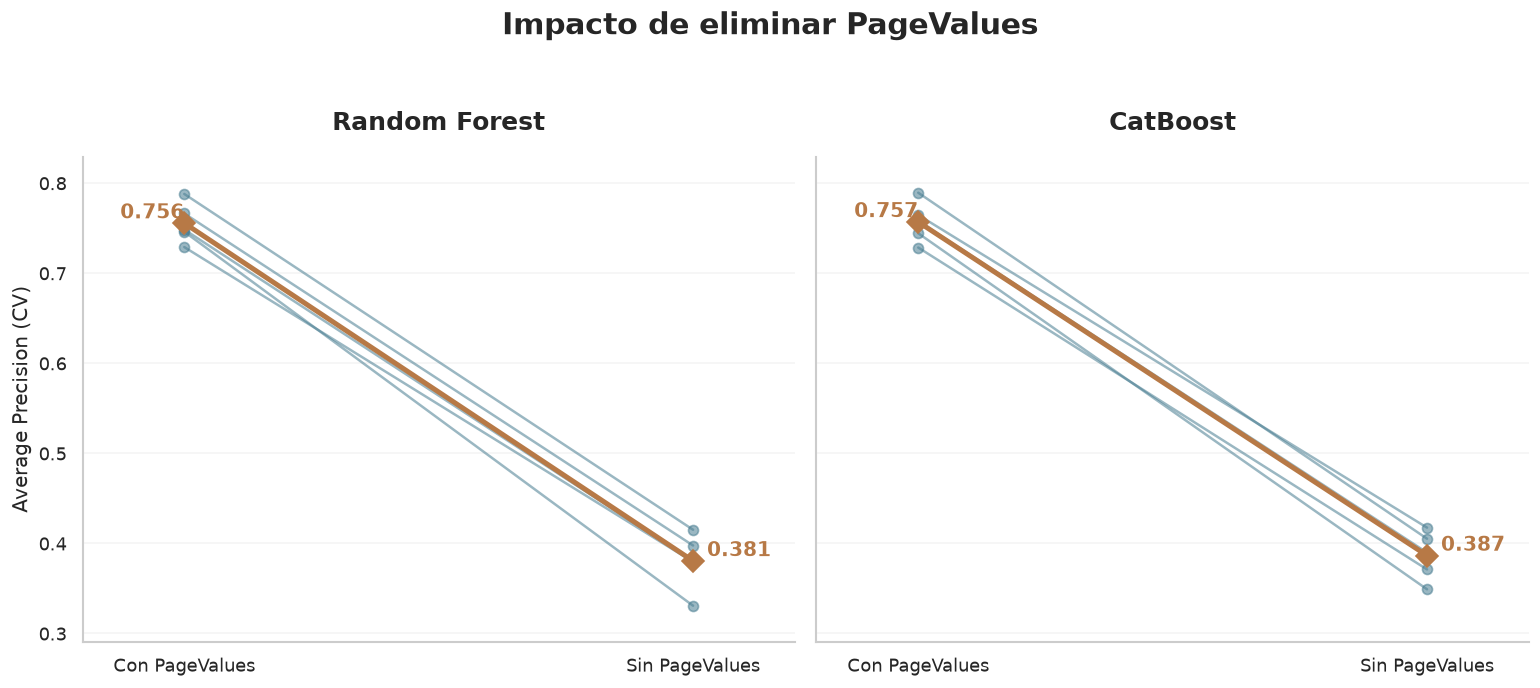

In [30]:
fig, axes = plt.subplots(
    1, 2, figsize=(13, 5.5), sharey=True
)

min_ap = detalle_page[["AP con", "AP sin"]].min().min()
max_ap = detalle_page[["AP con", "AP sin"]].max().max()

lim_inf = max(0, min_ap - 0.04)
lim_sup = min(1, max_ap + 0.04)

for ax, nombre in zip(
    axes, ["Random Forest", "CatBoost"]
):

    datos_modelo = (
        detalle_page[detalle_page["Modelo"] == nombre]
        .sort_values("Fold")
    )

    # Resultados individuales de los cinco folds
    for _, fila in datos_modelo.iterrows():
        ax.plot(
            [0, 1],
            [fila["AP con"], fila["AP sin"]],
            color="#487D91",
            marker="o",
            markersize=6,
            linewidth=1.5,
            alpha=0.55
        )

    # Rendimiento medio
    media_con = datos_modelo["AP con"].mean()
    media_sin = datos_modelo["AP sin"].mean()

    ax.plot(
        [0, 1],
        [media_con, media_sin],
        color="#B77946",
        marker="D",
        markersize=9,
        linewidth=3,
        zorder=5
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(
        ["Con PageValues", "Sin PageValues"]
    )

    ax.set_xlim(-0.2, 1.2)
    ax.set_ylim(lim_inf, lim_sup)

    ax.set_title(nombre, fontsize=15, pad=16)
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)

    ax.text(
        0, media_con,
        f"  {media_con:.3f}",
        ha="right",
        va="bottom",
        fontweight="bold",
        color="#B77946"
    )

    ax.text(
        1, media_sin,
        f"  {media_sin:.3f}",
        ha="left",
        va="bottom",
        fontweight="bold",
        color="#B77946"
    )

axes[0].set_ylabel("Average Precision (CV)")

fig.suptitle(
    "Impacto de eliminar PageValues",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- **Random Forest:** el AP disminuye de 0,7556 a 0,3806
  al eliminar PageValues (−0,3750).


- **CatBoost:** presenta una caída similar, de 0,7569 a
  0,3865 (−0,3704).


- La reducción aparece en los cinco folds de ambos modelos,
  confirmando una fuerte dependencia de esta característica.

  
- Sin PageValues, ambos algoritmos siguen superando la
  referencia de AP correspondiente al 15,6 % de compradores,
  aunque con un rendimiento considerablemente inferior.

**Decisión:** mantendremos PageValues en los modelos
principales, documentando sus requisitos de disponibilidad
temporal. Antes de cerrar el experimento, reajustaremos
los hiperparámetros de los modelos sin esta característica
para comprobar si es posible recuperar parte del rendimiento.

### 4.4. Reoptimización de los modelos sin PageValues

La eliminación de PageValues ha reducido considerablemente el
Average Precision de ambos algoritmos.

Sin embargo, los hiperparámetros utilizados habían sido
optimizados originalmente incluyendo esta característica.

Para comprobar si es posible recuperar parte del rendimiento,
realizamos una búsqueda reducida:

- **Random Forest:** ajustamos max_depth y min_samples_leaf.


- **CatBoost:** ajustamos depth y learning_rate.

Mantenemos fijos los demás hiperparámetros y las mismas cinco
particiones estratificadas, utilizando Average Precision
como criterio de selección.

In [31]:
parametros_rf_sin_page = {
    "clasificador__max_depth": [5, 8, 12],
    "clasificador__min_samples_leaf": [2, 8, 16]
}

busqueda_rf_sin_page = GridSearchCV(
    estimator=modelo_rf_sin_page,
    param_grid=parametros_rf_sin_page,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_rf_sin_page.fit(X_rf_sin_page, y_train)

print("RANDOM FOREST")
print("Mejores parámetros:", busqueda_rf_sin_page.best_params_)
print(f"AP sin PageValues (inicial): {tabla_page.loc['Random Forest', 'AP_sin']:.4f}")
print(f"AP sin PageValues (optimizado): {busqueda_rf_sin_page.best_score_:.4f}")


# --- Reoptimización de CatBoost sin PageValues ---

parametros_cb_sin_page = {
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.07]
}

busqueda_cb_sin_page = GridSearchCV(
    estimator=modelo_cb_sin_page,
    param_grid=parametros_cb_sin_page,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_cb_sin_page.fit(
    X_cb_sin_page,
    y_train,
    cat_features=variables_categoricas
)

print("\nCATBOOST")
print("Mejores parámetros:", busqueda_cb_sin_page.best_params_)
print(f"AP sin PageValues (inicial): {tabla_page.loc['CatBoost', 'AP_sin']:.4f}")
print(f"AP sin PageValues (optimizado): {busqueda_cb_sin_page.best_score_:.4f}")

RANDOM FOREST
Mejores parámetros: {'clasificador__max_depth': 12, 'clasificador__min_samples_leaf': 16}
AP sin PageValues (inicial): 0.3806
AP sin PageValues (optimizado): 0.3811

CATBOOST
Mejores parámetros: {'depth': 8, 'learning_rate': 0.03}
AP sin PageValues (inicial): 0.3865
AP sin PageValues (optimizado): 0.3865


### 4.5. Resultados de la reoptimización

Representamos el Average Precision medio de las configuraciones
evaluadas sin PageValues.

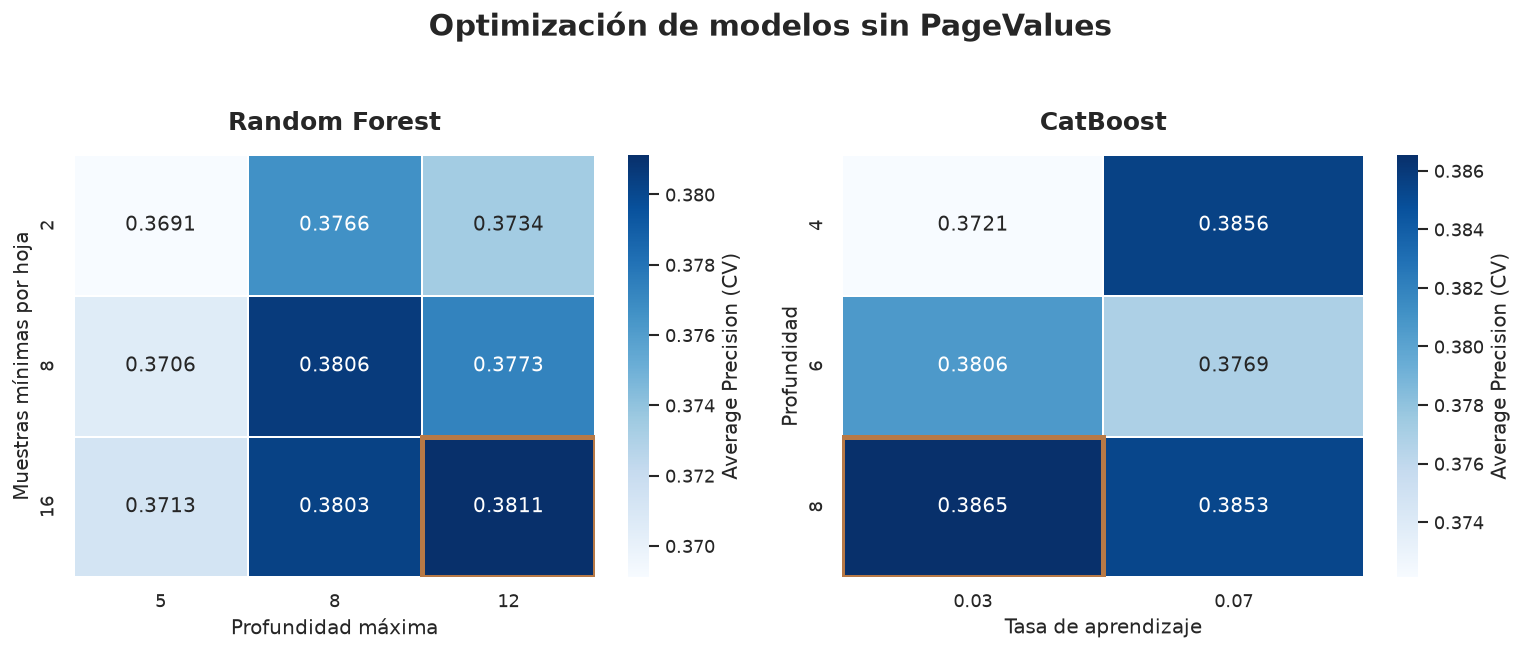

In [32]:
resultados_rf_sp = pd.DataFrame(
    busqueda_rf_sin_page.cv_results_
)

mapa_rf_sp = resultados_rf_sp.pivot(
    index="param_clasificador__min_samples_leaf",
    columns="param_clasificador__max_depth",
    values="mean_test_score"
).reindex(
    index=[2, 8, 16],
    columns=[5, 8, 12]
)

resultados_cb_sp = pd.DataFrame(
    busqueda_cb_sin_page.cv_results_
)

mapa_cb_sp = resultados_cb_sp.pivot(
    index="param_depth",
    columns="param_learning_rate",
    values="mean_test_score"
).reindex(
    index=[4, 6, 8],
    columns=[0.03, 0.07]
)

# Visualización

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

mapas = [
    (axes[0], mapa_rf_sp, "Random Forest",
     "Profundidad máxima", "Muestras mínimas por hoja"),
    (axes[1], mapa_cb_sp, "CatBoost",
     "Tasa de aprendizaje", "Profundidad")
]

for ax, mapa, titulo, eje_x, eje_y in mapas:

    sns.heatmap(
        mapa,
        annot=True,
        fmt=".4f",
        cmap="Blues",
        linewidths=1,
        linecolor="white",
        cbar_kws={"label": "Average Precision (CV)"},
        ax=ax
    )

    fila, columna = np.unravel_index(
        np.nanargmax(mapa.to_numpy()),
        mapa.shape
    )

    ax.add_patch(
        plt.Rectangle(
            (columna, fila),
            1, 1,
            fill=False,
            edgecolor="#B77946",
            linewidth=3
        )
    )

    ax.set_title(titulo, fontsize=15, pad=15)
    ax.set_xlabel(eje_x)
    ax.set_ylabel(eje_y)

fig.suptitle(
    "Optimización de modelos sin PageValues",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

### 4.6. Comparación final del rendimiento

Comparamos los resultados originales con PageValues, los
obtenidos tras eliminarlo y los alcanzados después de
reoptimizar cada algoritmo.

Esto permitirá cuantificar qué parte del rendimiento perdido
se recupera mediante el reajuste de hiperparámetros.

In [33]:
comparacion_page_final = pd.DataFrame({
    "Con PageValues": tabla_page["AP_con"],
    "Sin PageValues": tabla_page["AP_sin"],
    "Sin PageValues (optimizado)": pd.Series({
        "Random Forest": busqueda_rf_sin_page.best_score_,
        "CatBoost": busqueda_cb_sin_page.best_score_
    })
})

comparacion_page_final["Mejora por reajuste"] = (
    comparacion_page_final["Sin PageValues (optimizado)"]
    - comparacion_page_final["Sin PageValues"]
)

comparacion_page_final["Pérdida final"] = (
    comparacion_page_final["Sin PageValues (optimizado)"]
    - comparacion_page_final["Con PageValues"]
)

display(
    comparacion_page_final.style
    .format("{:.4f}")
    .background_gradient(
        subset=["Sin PageValues (optimizado)"],
        cmap="Blues"
    )
)

,Con PageValues,Sin PageValues,Sin PageValues (optimizado),Mejora por reajuste,Pérdida final
Random Forest,0.7556,0.3806,0.3811,0.0005,-0.3745
CatBoost,0.7569,0.3865,0.3865,0.0000,-0.3704


**Interpretación**

- **Random Forest:** la reoptimización mejora ligeramente el AP
  de 0,3806 a 0,3811 (+0,0005).


- **CatBoost:** el mejor resultado se mantiene en 0,3865,
  sin mejoras respecto a la configuración anterior.
- En ambos algoritmos, eliminar PageValues supone una caída
  aproximada de 0,37 puntos de AP que no se recupera al
  reajustar los hiperparámetros.

**Decisión:** finalizamos el experimento y conservamos PageValues
en los modelos principales, condicionando su aplicación real
a que pueda obtenerse una métrica equivalente antes de la compra.

## 5. Ajuste final de CatBoost con 22 características

Los experimentos de ingeniería de características han permitido
mejorar el Average Precision de CatBoost hasta 0,7569.

Sin embargo, los hiperparámetros utilizados se habían optimizado
con las 17 características originales.

Para buscar una configuración más adecuada al conjunto ampliado,
realizamos una optimización en dos fases:

1. **Búsqueda aleatoria:** exploración amplia de profundidad,
   tasa de aprendizaje, número de iteraciones y regularización L2.

   
2. **Búsqueda en cuadrícula:** refinamiento de las regiones más
   prometedoras identificadas en la primera fase.

Utilizaremos los mismos cinco folds estratificados y Average
Precision como criterio de selección, sin aplicar balanceo
ni utilizar el conjunto de prueba.

### 5.1. Exploración mediante RandomizedSearchCV

La búsqueda aleatoria permitirá evaluar diferentes combinaciones
de hiperparámetros sin recorrer exhaustivamente todo el espacio.

Seleccionaremos 20 configuraciones reproducibles con semilla 42.

In [34]:
from sklearn.model_selection import RandomizedSearchCV

# Preparación de CatBoost con 22 características

X_cat_final = X_train_fe.copy()

for columna in variables_categoricas:
    X_cat_final[columna] = X_cat_final[columna].astype(str)

modelo_cb_final = CatBoostClassifier(
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

# Espacio amplio de hiperparámetros

parametros_cb_random = {
    "depth": [4, 5, 6, 7, 8, 9, 10],
    "learning_rate": [0.01, 0.015, 0.02, 0.03, 0.05, 0.07, 0.10],
    "iterations": [150, 200, 300, 450, 600],
    "l2_leaf_reg": [1, 2, 3, 5, 8, 12]
}

busqueda_cb_random = RandomizedSearchCV(
    estimator=modelo_cb_final,
    param_distributions=parametros_cb_random,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

busqueda_cb_random.fit(
    X_cat_final,
    y_train,
    cat_features=variables_categoricas
)

ap_anterior = tabla_fe.loc["CatBoost", "Ampliadas (22)"]

print("\nMejores hiperparámetros:")
print(busqueda_cb_random.best_params_)

print(f"\nAP anterior: {ap_anterior:.4f}")
print(f"AP búsqueda aleatoria: {busqueda_cb_random.best_score_:.4f}")
print(f"Diferencia: {busqueda_cb_random.best_score_ - ap_anterior:+.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores hiperparámetros:
{'learning_rate': 0.02, 'l2_leaf_reg': 1, 'iterations': 300, 'depth': 8}

AP anterior: 0.7569
AP búsqueda aleatoria: 0.7583
Diferencia: +0.0014


#### Resultados de la búsqueda aleatoria

Ordenamos las configuraciones por Average Precision para
identificar qué combinaciones ofrecen los mejores resultados.

Analizaremos los valores de los cuatro hiperparámetros
antes de definir el espacio de búsqueda del refinamiento.

In [35]:
resultados_random = pd.DataFrame(
    busqueda_cb_random.cv_results_
)

columnas = {
    "param_depth": "Profundidad",
    "param_learning_rate": "Learning rate",
    "param_iterations": "Iteraciones",
    "param_l2_leaf_reg": "Regularización L2",
    "mean_test_score": "AP medio",
    "std_test_score": "Desv. AP"
}

top_random = (
    resultados_random[list(columnas)]
    .rename(columns=columnas)
    .sort_values("AP medio", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(
    top_random.style
    .format({
        "Learning rate": "{:.3f}",
        "AP medio": "{:.4f}",
        "Desv. AP": "{:.4f}"
    })
    .background_gradient(
        subset=["AP medio"],
        cmap="Blues"
    )
)

,Profundidad,Learning rate,Iteraciones,Regularización L2,AP medio,Desv. AP
0,8,0.020,300,1,0.7583,0.0205
1,6,0.015,600,8,0.7565,0.0214
2,7,0.030,300,12,0.7560,0.0212
3,10,0.020,450,12,0.7553,0.0214
4,6,0.050,200,8,0.7531,0.0208
5,6,0.030,150,2,0.7517,0.0224
6,4,0.050,200,5,0.7514,0.0216
7,5,0.070,200,3,0.7513,0.0209
8,4,0.020,600,3,0.7508,0.0219
9,5,0.050,450,5,0.7506,0.0222


### 5.2. Refinamiento mediante GridSearchCV

La búsqueda aleatoria ha identificado una configuración con
AP = 0,7583, ligeramente superior al 0,7569 anterior.

El mejor resultado aparece con profundidad 8, tasa de aprendizaje
0,02, 300 iteraciones y regularización L2 igual a 1.

Refinamos esta región mediante GridSearchCV, explorando
profundidades y tasas de aprendizaje próximas, y comparando
dos intensidades de regularización.

Mantenemos 300 iteraciones para limitar el coste computacional.
La búsqueda conservará los mismos cinco folds estratificados.

In [36]:
parametros_cb_grid = {
    "depth": [7, 8, 9],
    "learning_rate": [0.015, 0.020, 0.025],
    "l2_leaf_reg": [1, 3]
}

modelo_cb_grid = CatBoostClassifier(
    iterations=300,
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

busqueda_cb_grid = GridSearchCV(
    estimator=modelo_cb_grid,
    param_grid=parametros_cb_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_cb_grid.fit(
    X_cat_final,
    y_train,
    cat_features=variables_categoricas
)

print("Mejores hiperparámetros:")
print(busqueda_cb_grid.best_params_)

print(f"\nAP anterior: {ap_anterior:.4f}")
print(f"AP búsqueda aleatoria: {busqueda_cb_random.best_score_:.4f}")
print(f"AP refinamiento: {busqueda_cb_grid.best_score_:.4f}")

Mejores hiperparámetros:
{'depth': 8, 'l2_leaf_reg': 1, 'learning_rate': 0.02}

AP anterior: 0.7569
AP búsqueda aleatoria: 0.7583
AP refinamiento: 0.7583


#### Resultados del refinamiento

Representamos las 18 configuraciones mediante dos mapas de
calor, uno para cada intensidad de regularización L2.

Comparamos la profundidad y la tasa de aprendizaje utilizando
la misma escala de colores, destacando la mejor configuración.

Esto permitirá comprobar si la búsqueda ha encontrado una
región estable y si el refinamiento mejora la exploración inicial.

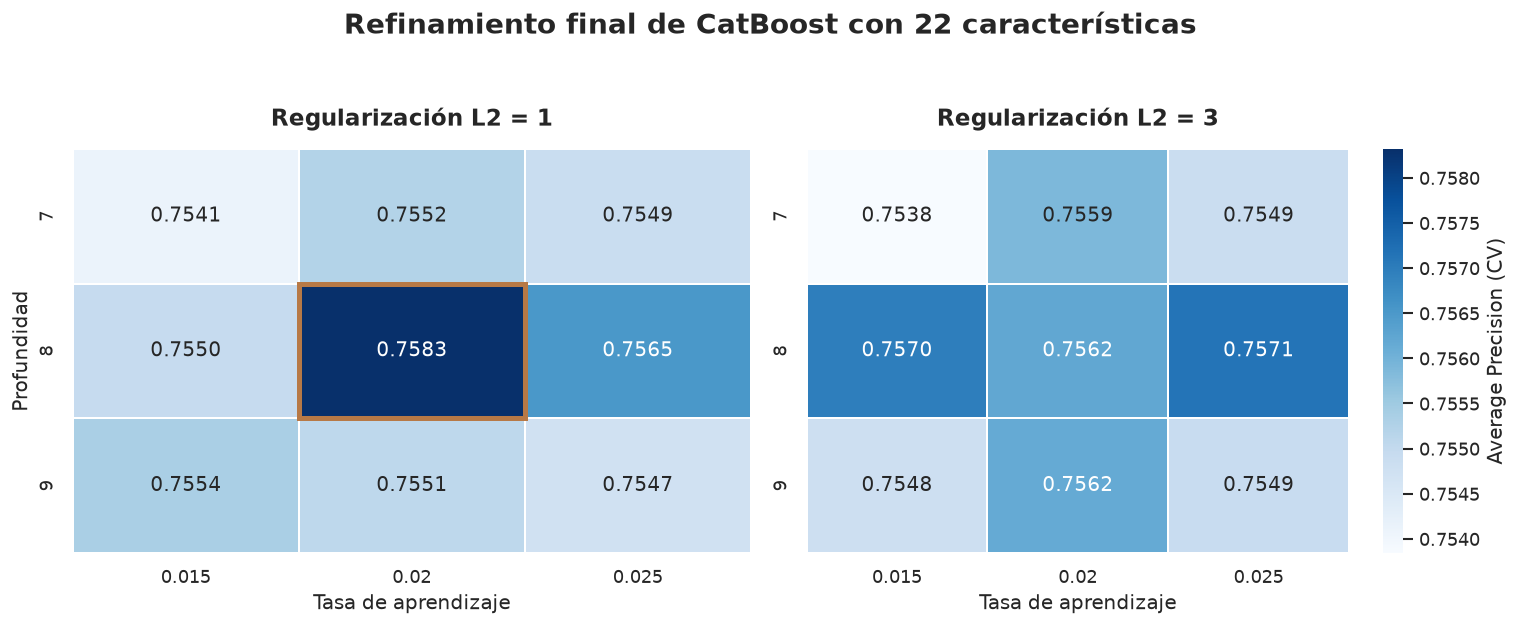

In [37]:
# Heatmaps del refinamiento final de CatBoost

resultados_grid = pd.DataFrame(busqueda_cb_grid.cv_results_)

resultados_grid["Profundidad"] = (
    resultados_grid["param_depth"].astype(int)
)

resultados_grid["Learning rate"] = (
    resultados_grid["param_learning_rate"].astype(float)
)

resultados_grid["L2"] = (
    resultados_grid["param_l2_leaf_reg"].astype(int)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

vmin = resultados_grid["mean_test_score"].min()
vmax = resultados_grid["mean_test_score"].max()

for i, (ax, l2) in enumerate(zip(axes, [1, 3])):

    subset = resultados_grid[resultados_grid["L2"] == l2]

    mapa = subset.pivot(
        index="Profundidad",
        columns="Learning rate",
        values="mean_test_score"
    ).reindex(
        index=[7, 8, 9],
        columns=[0.015, 0.020, 0.025]
    )

    sns.heatmap(
        mapa,
        annot=True,
        fmt=".4f",
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        linewidths=1,
        linecolor="white",
        cbar=(i == 1),
        cbar_kws={"label": "Average Precision (CV)"},
        ax=ax
    )

    if l2 == busqueda_cb_grid.best_params_["l2_leaf_reg"]:

        fila, columna = np.unravel_index(
            np.nanargmax(mapa.to_numpy()),
            mapa.shape
        )

        ax.add_patch(
            plt.Rectangle(
                (columna, fila),
                1, 1,
                fill=False,
                edgecolor="#B77946",
                linewidth=3
            )
        )

    ax.set_title(f"Regularización L2 = {l2}", fontsize=14, pad=14)
    ax.set_xlabel("Tasa de aprendizaje")
    ax.set_ylabel("Profundidad" if i == 0 else "")

fig.suptitle(
    "Refinamiento final de CatBoost con 22 características",
    fontsize=17,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- La mejor configuración mantiene un **AP de 0,7583**, con
  profundidad 8, learning_rate=0.02, 300 iteraciones y
  regularización L2=1.


- El refinamiento confirma el resultado de la búsqueda
  aleatoria, sin encontrar mejoras adicionales.

  
- Las configuraciones próximas ofrecen resultados similares,
  por lo que no se justifican nuevas búsquedas.

**Decisión:** seleccionamos esta configuración para CatBoost
con las 22 características y finalizamos la optimización.

## 6. Conclusiones y selección de modelos candidatos

Los experimentos nos han permitido estudiar distintas mejoras
sobre los modelos optimizados, manteniendo el conjunto de
prueba reservado para la evaluación final.

| Experimento | Resultado | Decisión |
|---|---|---|
| **Ingeniería de características** | Las cinco variables derivadas mejoran CatBoost, pero no Random Forest. | Conservar 22 características en CatBoost y 17 en Random Forest. |
| **Tratamiento del desequilibrio** | La ponderación y SMOTENC no mejoran AP. Random Oversampling reajustado prácticamente iguala al modelo original. | Mantener ambos modelos sin balanceo. |
| **Exclusión de PageValues** | El AP cae hasta aproximadamente 0,38 en ambos modelos. | Conservar PageValues en el escenario principal, condicionando su uso a la disponibilidad temporal de una métrica equivalente. |
| **Reoptimización final** | CatBoost alcanza un AP de 0,7583 con las 22 características. | Actualizar sus hiperparámetros para la siguiente etapa. |

### Modelos candidatos

| Modelo | Características | Balanceo | AP (CV) |
|---|---:|---|---:|
| **CatBoost** | 22 | Ninguno | **0,7583** |
| **Random Forest** | 17 | Ninguno | 0,7556 |

CatBoost presenta el mayor Average Precision, aunque la
diferencia respecto a Random Forest es muy pequeña.

Por ello, lo seleccionamos como **candidato principal para
el análisis de interpretabilidad**, manteniendo Random Forest
como alternativa competitiva.

Los resultados obtenidos están condicionados por el proceso
de selección de hiperparámetros sobre los mismos folds.
La evaluación final independiente sigue pendiente.

### Siguiente etapa

Analizaremos la importancia y contribución de las variables
mediante SHAP, investigando qué patrones de navegación se
asocian con una mayor o menor intención de compra y qué
posibles barreras comerciales pueden identificarse.